# Dota 2 Bootcamp — единый исследовательский ноутбук (Colab + Trino)

**Кейсы:** №03 Roshan, №16 Winner, №19 Duration.

Ноутбук читает опубликованные данные Lakehouse через Trino и исследует результаты. Он не создаёт и не изменяет таблицы Lakehouse, не запускает Spark ETL и не публикует производственные модели. Все SQL-запросы предназначены для чтения.

# Dota 2 Data Engineering Bootcamp — презентация проекта

**Кейсы № 03 · 16 · 19**  
Томск, 12–15 ноября 2026 года  
Аналитика игровой меты на основе данных Dota 2

**Команда проекта:** Емельянов Кирилл Дмитриевич · Кренев Михаил Александрович · Машков Юрий Сергеевич · Намажап Чингис Альбертович.

## Бизнес-задача и ожидаемый результат

Заказчик — аналитический отдел киберспортивной организации. Матчи Dota 2 содержат большой объём разрозненных игровых событий. Без единой модели данных сложно быстро отвечать, какие действия связаны с победой, как контроль Рошана соотносится с исходом и какие ранние события помогают оценить длительность матча.

**Цель проекта:** преобразовать сырые игровые события в проверяемые аналитические показатели, воспроизводимые витрины и дашборды.

| Кейс | Аналитический вопрос | Тип результата |
|---|---|---|
| **03 · Roshan** | Связан ли контроль Рошана с вероятностью победы? | Анализ win rate по первому Рошану, количеству и доле контроля |
| **16 · Winner** | Можно ли предсказать победителя по первым 15 минутам? | Классификация `radiant_win` |
| **19 · Duration** | Можно ли оценить длительность матча по первым 15 минутам? | Регрессия `duration` |

Для Winner и Duration в признаки включаются только события из интервала **[0, 900) секунд**. События после 15-й минуты исключены, чтобы не использовать информацию из будущего матча.

## Общая модель данных и архитектура

Исходные данные поступают из PostgreSQL (`matches`, `match_players`, `players`, `npcs`) и MongoDB (игровые события). Связи между системами строятся по `match_id`; сопоставление игрока выполняется через `account_id` и `steam_account_id`.

Рабочий поток проекта: **источники → RAW → STAGE → MART → Trino → Superset / аналитические ноутбуки**.

Платформенный слой использует Spark для преобразования Iceberg-таблиц, публикацию через `publish_table`, а также Airflow для оркестрации. Data Lineage фиксируется через OpenLineage / Marquez. Superset подключается к опубликованным витринам через Trino.


### ER-диаграмма источников

**Исходная модель PostgreSQL и MongoDB**

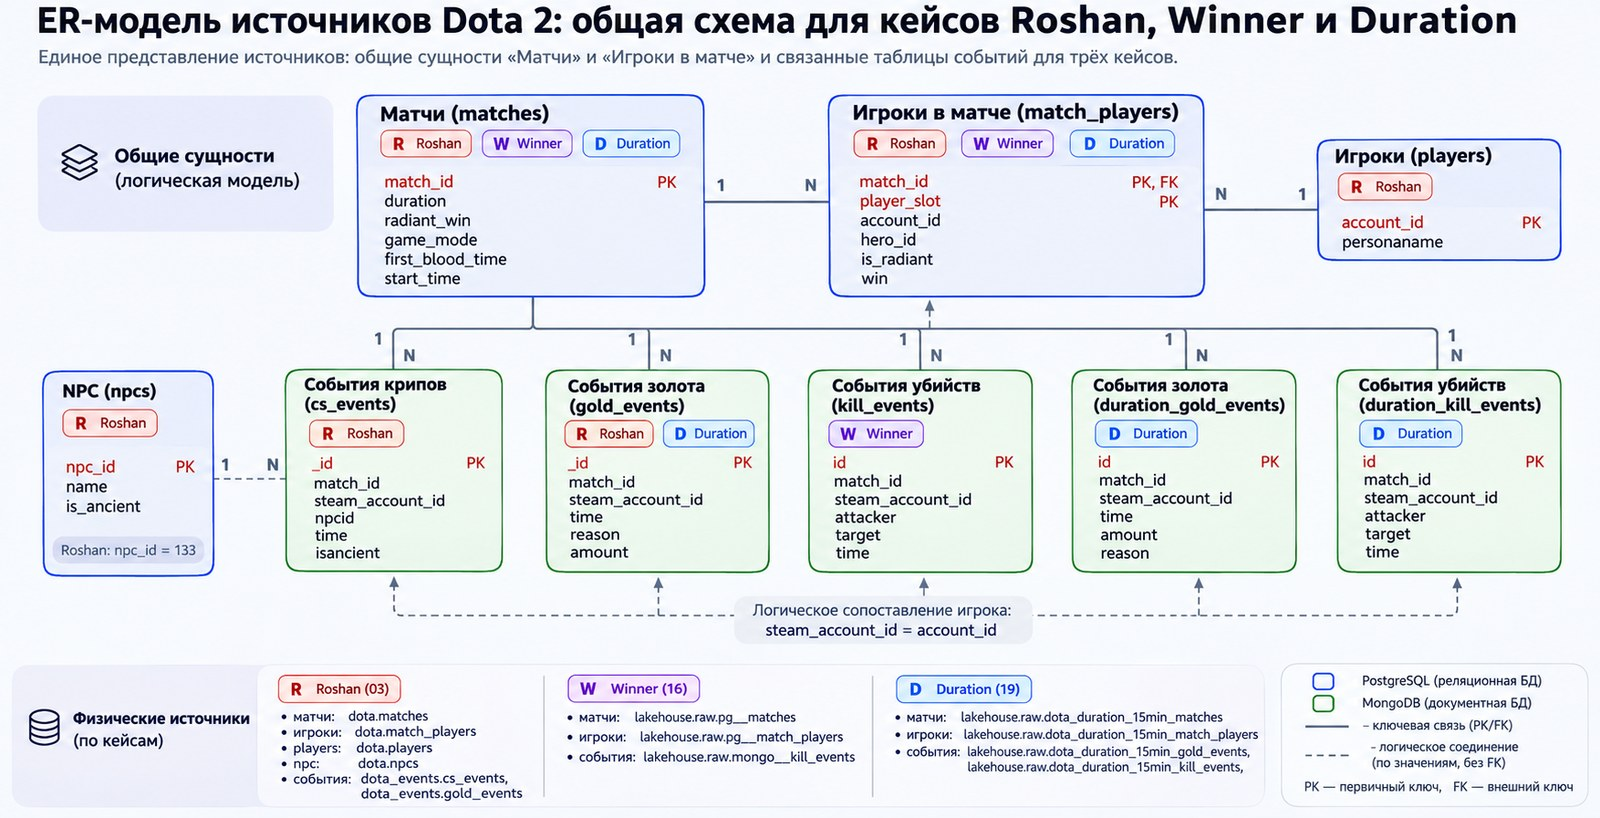


## Общие правила подготовки данных

1. **Matches:** одна запись на `match_id`, проверка ключа, типов и длительности.
2. **Players:** проверка уникальности игрока в матче; неоднозначные сопоставления не размножают строки.
3. **Events:** проверка `match_id`, времени, дубликатов и типа события; для Winner и Duration применяется окно [0, 900).
4. **Агрегация:** Roshan агрегируется до матча и команды; Winner и Duration — до матча.
5. **Data Quality:** проверяются NULL, дубликаты, orphan `match_id`, диапазоны и покрытие. Отсутствие события отделяется от отсутствия данных.

В презентационном срезе для Duration было зафиксировано 20 972 матча, а gold events присутствовали у 13 043 (~62,2%). Эти цифры относятся к профилированию исходного набора и не подменяют размер фактической MART в исследовательском разделе Duration.

Путь подготовки: Spark читает RAW, проверяет схемы и ключи, формирует STAGE, строит отдельные MART для трёх кейсов и публикует их в Iceberg. Airflow управляет запусками; Trino предоставляет SQL-доступ к витринам, Superset — BI-визуализацию.

## Содержание ноутбука

Перед аналитикой выполняются общие проверки каталога Lakehouse и источников. Затем кейсы разобраны в порядке презентации: **03 Roshan → 16 Winner → 19 Duration**. В каждом разделе вместе расположены постановка гипотез, проверочный код, сохранённые результаты, ограничения, Airflow DAG, Data Lineage и Superset Dashboard.

## 1. Подключение к Trino

Используется подтверждённый адрес `http://84.201.171.253:8080`. Путь `/ui/` для Python-клиента не нужен.

Если сервер недавно перезапущен, он может некоторое время отвечать `SERVER_STARTING_UP`. Ячейка подключения повторяет простую проверку `SELECT 1`.

In [1]:
!pip -q install trino

In [2]:
import time
import pandas as pd
from IPython.display import display
from trino.dbapi import connect
from trino.exceptions import TrinoQueryError

TRINO_HOST = "84.201.171.253"
TRINO_PORT = 8080
TRINO_USER = "colab"
TRINO_CATALOG = "lakehouse"

conn = connect(
    host=TRINO_HOST,
    port=TRINO_PORT,
    user=TRINO_USER,
    catalog=TRINO_CATALOG,
    schema="raw",
    http_scheme="http",
)

cursor = conn.cursor()

connected = False
for attempt in range(6):
    try:
        cursor.execute("SELECT 1")
        print("Trino готов:", cursor.fetchall())
        connected = True
        break
    except TrinoQueryError as exc:
        if "SERVER_STARTING_UP" not in str(exc) or attempt == 5:
            raise
        print(f"Trino ещё запускается; попытка {attempt + 1}/6")
        time.sleep(20)

if not connected:
    raise RuntimeError("Не удалось дождаться готовности Trino.")

Trino готов: [[1]]


## 2. Инвентаризация Lakehouse

Проверяются доступные каталоги и схемы Lakehouse; наличие каждой таблицы подтверждается по каталогу.

In [3]:
def query_df(sql):
    cursor.execute(sql)
    rows = cursor.fetchall()
    columns = [item[0] for item in cursor.description] if cursor.description else []
    return pd.DataFrame(rows, columns=columns)

display(query_df("SHOW CATALOGS"))
display(query_df("SHOW SCHEMAS FROM lakehouse"))

,Catalog
0,lakehouse
1,system


,Schema
0,information_schema
1,mart
2,raw
3,stage
4,system


In [4]:
for schema_name in ["raw", "stage", "mart"]:
    print(f"\\n=== lakehouse.{schema_name} ===")
    display(query_df(f"SHOW TABLES FROM lakehouse.{schema_name}"))

\n=== lakehouse.raw ===


,Table
0,ability_category_map
1,dota_duration_15min_gold_events
2,dota_duration_15min_kill_events
3,dota_duration_15min_match_players
4,dota_duration_15min_matches
...,...
88,stage_talents
89,stage_wards
90,tower_first_death_matches
91,tower_first_death_tower_damage


\n=== lakehouse.stage ===


,Table
0,abilities
1,bounty_05_match_events
2,bounty_05_match_gold
3,buyback
4,buyback_context
...,...
110,t1_c13_matches
111,t1_c13_players
112,t1_c13_tower_hits
113,talents


\n=== lakehouse.mart ===


,Table
0,bounty_05_outcomes
1,buyback1_mart
2,buyback_events
3,case13_match_summary
4,case13_tower_ability
...,...
71,t1_c13_hero_tower_damage
72,t1_c13_team_early_push
73,t1_c13_team_early_push_v2
74,team_buybacks


## 3. Проверка исходных таблиц для трёх кейсов

Список взят из исходного ноутбука реализации. Для Roshan отдельно используется `stage.demo_roshan_kills`; остальные перечисленные источники находятся в RAW.

Отсутствующие источники фиксируются в статусе инвентаризации и не создаются вручную из Colab.

In [5]:
SOURCE_TABLES = [
    "lakehouse.raw.pg__matches",
    "lakehouse.raw.pg__match_players",
    "lakehouse.raw.mongo__kill_events",
    "lakehouse.raw.dota_duration_15min_matches",
    "lakehouse.raw.dota_duration_15min_match_players",
    "lakehouse.raw.dota_duration_15min_gold_events",
    "lakehouse.raw.dota_duration_15min_kill_events",
    "lakehouse.stage.demo_roshan_kills",
]

available_tables = query_df("""
    SELECT table_schema, table_name
    FROM lakehouse.information_schema.tables
    WHERE table_schema IN ('raw', 'stage', 'mart')
    ORDER BY table_schema, table_name
""")

available_names = {
    f"lakehouse.{row.table_schema}.{row.table_name}"
    for row in available_tables.itertuples(index=False)
}

source_status = pd.DataFrame({
    "table_name": SOURCE_TABLES,
    "exists": [name in available_names for name in SOURCE_TABLES],
})
display(source_status)

missing_sources = source_status.loc[~source_status["exists"], "table_name"].tolist()
if missing_sources:
    print("Не найдены источники:", *missing_sources, sep="\\n- ")
else:
    print("Все перечисленные исходные таблицы найдены.")

,table_name,exists
0,lakehouse.raw.pg__matches,True
1,lakehouse.raw.pg__match_players,True
2,lakehouse.raw.mongo__kill_events,True
3,lakehouse.raw.dota_duration_15min_matches,True
4,lakehouse.raw.dota_duration_15min_match_players,True
5,lakehouse.raw.dota_duration_15min_gold_events,True
6,lakehouse.raw.dota_duration_15min_kill_events,True
7,lakehouse.stage.demo_roshan_kills,True


Все перечисленные исходные таблицы найдены.


## 4. Фактические схемы источников

Сверяем реальные названия и типы столбцов с контрактами исходного проекта. Это особенно важно перед созданием SQL-процессов в портале: код процесса должен опираться на фактическую схему, а не на предположения.

In [6]:
for table_name in SOURCE_TABLES:
    if table_name not in available_names:
        continue
    print(f"\\n--- {table_name} ---")
    display(query_df(f"DESCRIBE {table_name}"))

\n--- lakehouse.raw.pg__matches ---


,Column,Type,Extra,Comment
0,barracks_status_dire,integer,,Битовая маска казарм Dire
1,barracks_status_radiant,integer,,Битовая маска казарм Radiant
2,cluster,integer,,ID кластера (регион)
3,dire_score,integer,,Убийств Dire
4,discover_run_id,integer,,ID discover-запуска
5,duration,integer,,Длительность (сек)
6,enrich_run_id,integer,,ID enrich-запуска
7,enrichment_attempts,integer,,Попыток обогащения (макс. 5)
8,first_blood_time,integer,,Время первого убийства (сек)
9,game_mode,integer,,ID режима игры


\n--- lakehouse.raw.pg__match_players ---


,Column,Type,Extra,Comment
0,account_id,bigint,,Steam account ID
1,aghanims_scepter,boolean,,true если куплен Scepter
2,aghanims_shard,boolean,,true если куплен Shard
3,assists,integer,,Ассисты
4,backpack_0,integer,,ID предмета в рюкзаке 0
5,backpack_1,integer,,ID предмета в рюкзаке 1
6,backpack_2,integer,,ID предмета в рюкзаке 2
7,deaths,integer,,Смерти
8,denies,integer,,Denies
9,gold,integer,,Золото на конец матча


\n--- lakehouse.raw.mongo__kill_events ---


,Column,Type,Extra,Comment
0,assist,integer,,steamAccountId ассиста
1,attacker,integer,,steamAccountId убийцы
2,byability,integer,,ID способности
3,byitem,integer,,ID предмета
4,gold,integer,,Золото за убийство
5,id,varchar,,Уникальный ID документа
6,isfromillusion,boolean,,Убийца — иллюзия
7,isgank,boolean,,Ганк
8,isinvisible,boolean,,Убийца невидим
9,isruneeffected,boolean,,Под эффектом руны


... (6 outputs left out)

\n--- lakehouse.raw.dota_duration_15min_kill_events ---


,Column,Type,Extra,Comment
0,id,varchar,,
1,match_id,bigint,,
2,steam_account_id,bigint,,
3,attacker,bigint,,
4,target,bigint,,
5,time,integer,,
6,src_modified_stamp,timestamp(6) with time zone,,
7,sys_insert_stamp,timestamp(6) with time zone,,


\n--- lakehouse.stage.demo_roshan_kills ---


,Column,Type,Extra,Comment
0,match_id,bigint,,ID матча
1,roshan_time_sec,integer,,
2,radiant_kill,integer,,


## 5. Базовое профилирование RAW

Эти проверки только читают данные. Они помогают понять объёмы, ключи и пропуски перед проектированием STAGE.

Полные `COUNT(*)` могут выполняться дольше, поэтому запускай их после проверки доступности таблиц.

In [7]:
PROFILE_QUERIES = {
    "matches": """
        SELECT
            COUNT(*) AS rows_count,
            COUNT(DISTINCT match_id) AS distinct_matches,
            COUNT_IF(match_id IS NULL) AS null_match_id,
            COUNT_IF(radiant_win IS NULL) AS null_radiant_win,
            COUNT_IF(duration IS NULL) AS null_duration
        FROM lakehouse.raw.pg__matches
    """,
    "match_players": """
        SELECT
            COUNT(*) AS rows_count,
            COUNT(DISTINCT match_id) AS distinct_matches,
            COUNT_IF(match_id IS NULL) AS null_match_id,
            COUNT_IF(player_slot IS NULL) AS null_player_slot,
            COUNT_IF(account_id IS NULL) AS null_account_id,
            COUNT_IF(hero_id IS NULL) AS null_hero_id
        FROM lakehouse.raw.pg__match_players
    """,
    "kill_events": """
        SELECT
            COUNT(*) AS rows_count,
            COUNT(DISTINCT match_id) AS distinct_matches,
            COUNT_IF(match_id IS NULL) AS null_match_id,
            COUNT_IF(time IS NULL) AS null_time,
            COUNT_IF(steam_account_id IS NULL) AS null_steam_account_id
        FROM lakehouse.raw.mongo__kill_events
    """,
}

for label, sql in PROFILE_QUERIES.items():
    print(f"\\n=== {label} ===")
    display(query_df(sql))

\n=== matches ===


,rows_count,distinct_matches,null_match_id,null_radiant_win,null_duration
0,325095,325095,0,0,0


\n=== match_players ===


,rows_count,distinct_matches,null_match_id,null_player_slot,null_account_id,null_hero_id
0,4925512,492560,0,0,0,0


\n=== kill_events ===


,rows_count,distinct_matches,null_match_id,null_time,null_steam_account_id
0,25121357,325775,0,0,0


## 6. Проверка окна первых 15 минут

Для Winner и Duration принципиально важно использовать только события в интервале `[0, 900)`. Следующие запросы оценивают покрытие и не создают признаки или таблицы.

In [8]:
display(query_df("""
    SELECT
        COUNT(*) AS all_kill_events,
        COUNT_IF(time >= 0 AND time < 900) AS events_0_900,
        COUNT_IF(time IS NULL) AS events_without_time,
        COUNT(DISTINCT IF(time >= 0 AND time < 900, match_id, NULL)) AS matches_with_early_kills
    FROM lakehouse.raw.mongo__kill_events
"""))

display(query_df("""
    SELECT
        COUNT(*) AS matches_count,
        COUNT_IF(duration IS NULL) AS null_duration,
        COUNT_IF(duration <= 900) AS matches_duration_le_15m,
        COUNT_IF(duration > 900) AS matches_duration_gt_15m
    FROM lakehouse.raw.dota_duration_15min_matches
"""))

,all_kill_events,events_0_900,events_without_time,matches_with_early_kills
0,25121357,9696372,0,325769


,matches_count,null_duration,matches_duration_le_15m,matches_duration_gt_15m
0,20972,0,116,20856


## 7. Проверка уже опубликованных STAGE/MART

Здесь мы не создаём витрины, а выясняем, какие результаты уже опубликованы платформенными процессами.

Имена ниже взяты из контрактов и целевых таблиц исходного проекта. Отсутствие таблицы отражается в результате проверки доступности.

In [9]:
EXPECTED_OUTPUTS = [
    "lakehouse.stage.practice_case_bootcamp_matches",
    "lakehouse.stage.practice_case_bootcamp_match_players",
    "lakehouse.stage.practice_case_03_roshan",
    "lakehouse.stage.practice_case_16_winner_features_15m",
    "lakehouse.mart.practice_case_bootcamp_match_overview",
    "lakehouse.mart.practice_case_bootcamp_roshan_effect",
    "lakehouse.mart.practice_case_16_winner_dataset",
    "lakehouse.mart.practice_case_16_winner_metrics",
    "lakehouse.mart.practice_case_16_winner_holdout_predictions",
    "lakehouse.mart.practice_case_16_winner_confusion",
    "lakehouse.mart.practice_case_19_duration_features",
    "lakehouse.mart.practice_case_19_duration_metrics",
    "lakehouse.mart.practice_case_19_duration_holdout_predictions",
]

output_status = pd.DataFrame({
    "table_name": EXPECTED_OUTPUTS,
    "exists": [name in available_names for name in EXPECTED_OUTPUTS],
})
display(output_status)

,table_name,exists
0,lakehouse.stage.practice_case_bootcamp_matches,False
1,lakehouse.stage.practice_case_bootcamp_match_p...,False
2,lakehouse.stage.practice_case_03_roshan,True
3,lakehouse.stage.practice_case_16_winner_featur...,False
4,lakehouse.mart.practice_case_bootcamp_match_ov...,False
5,lakehouse.mart.practice_case_bootcamp_roshan_e...,False
6,lakehouse.mart.practice_case_16_winner_dataset,False
7,lakehouse.mart.practice_case_16_winner_metrics,False
8,lakehouse.mart.practice_case_16_winner_holdout...,False
9,lakehouse.mart.practice_case_16_winner_confusion,False


## 8. Проверки качества опубликованных датасетов

Запускай только для таблиц, которые отмечены как существующие в предыдущей ячейке. Запросы ниже проверяют базовые контракты: одна строка на матч, заполненность ключа и target.

Контроль выполняется по фактическим именам и типам столбцов, возвращённым `DESCRIBE`.

In [10]:
def table_exists(full_name):
    return full_name in available_names

quality_checks = {
    "Winner": (
        "lakehouse.mart.practice_case_16_winner_dataset",
        """
        SELECT
            COUNT(*) AS rows_count,
            COUNT(DISTINCT match_id) AS distinct_matches,
            COUNT_IF(match_id IS NULL) AS null_match_id,
            COUNT_IF(radiant_win IS NULL) AS null_target
        FROM lakehouse.mart.practice_case_16_winner_dataset
        """
    ),
    "Duration": (
        "lakehouse.mart.practice_case_19_duration_features",
        """
        SELECT
            COUNT(*) AS rows_count,
            COUNT(DISTINCT match_id) AS distinct_matches,
            COUNT_IF(match_id IS NULL) AS null_match_id,
            COUNT_IF(duration IS NULL) AS null_target
        FROM lakehouse.mart.practice_case_19_duration_features
        """
    ),
}

for label, (table_name, sql) in quality_checks.items():
    print(f"\\n=== {label} ===")
    if table_exists(table_name):
        display(query_df(sql))
    else:
        print(f"Пропуск: таблица пока не найдена — {table_name}")

\n=== Winner ===
Пропуск: таблица пока не найдена — lakehouse.mart.practice_case_16_winner_dataset
\n=== Duration ===
Пропуск: таблица пока не найдена — lakehouse.mart.practice_case_19_duration_features


## 9. Кейс №03 Roshan — контроль объекта и исход матча

**Аналитический вопрос:** связан ли ранний или повторный контроль Рошана с более высокой вероятностью победы команды?

### Гипотезы и результаты

| ID | Гипотеза | Результат презентационного среза | Вывод |
|---|---|---|---|
| **R1** | Первый Рошан связан с победой команды, которая его забрала | При первом Рошане у Radiant win rate Radiant — **76,53%** (`n=98 659`); при первом Рошане у Dire — **26,04%** (`n=99 065`). Без Рошана — **54,94%** (`n=123 542`), база по всем матчам — **52,66%** (`n=321 266`). 95% ДИ: Radiant 76,27–76,80%; Dire 25,76–26,31%; без Рошана 54,66–55,21%. | **Подтверждена по направлению.** Разрыв Radiant first-Roshan vs база — около **+23,9 п.п.** |
| **R2** | Контроль стороны и вероятность победы: сторона, забравшая Рошана, должна определяться надёжно | Сторона определялась по last hit из `cs_events` для **66,5%** убийств, затем по командной выплате из `gold_events` для **28,6%**. Неизвестная сторона осталась у **4,93%** событий. В `matches` отсутствовали 1 761 матч (0,86%). | **Решена как правило качества данных.** Неопределённые события не следует молча относить к одной из команд. |
| **R3** | Чем больше убийств Рошана у Radiant, тем выше его win rate | Win rate по числу убийств Рошана у Radiant: `0` — **18,23%**; `1` — **73,84%**; `2` — **76,94%**; `3` — **74,54%**; `4+` — **74,04%**. | **Не подтверждена в линейной форме.** После первого Рошана наблюдается плато, а не постоянный рост. |
| **H2b** | Чем выше доля контроля Рошана у Radiant, тем выше win rate Radiant | `0%` — **18,23%**; `1–49%` — **42,95%**; `50–74%` — **51,94%**; `75–99%` — **60,94%**; `100%` — **85,07%**. | **Подтверждена по направлению.** Наблюдается монотонный рост. |
| **R4** | Поздний Рошан после 45-й минуты слабее связан с исходом матча | Разрыв сохраняется в матчах короче 50 минут: для интервала 10–19 минут — 95,9% против 7,5%; в 60–69 минут — 50,5% против 47,3%; после 70 минут — примерно 50/50. | **Частично подтверждена.** В очень длинных матчах показатель почти перестаёт различать команды. |

Результаты описывают ассоциацию, а не причинный эффект: команда может получать возможность забрать Рошана уже благодаря существующему преимуществу. Для каждой группы важны размер выборки и 95% интервал Уилсона.

### Airflow DAG — Case 03 Roshan

**DAG: подготовка Roshan STAGE и MART**

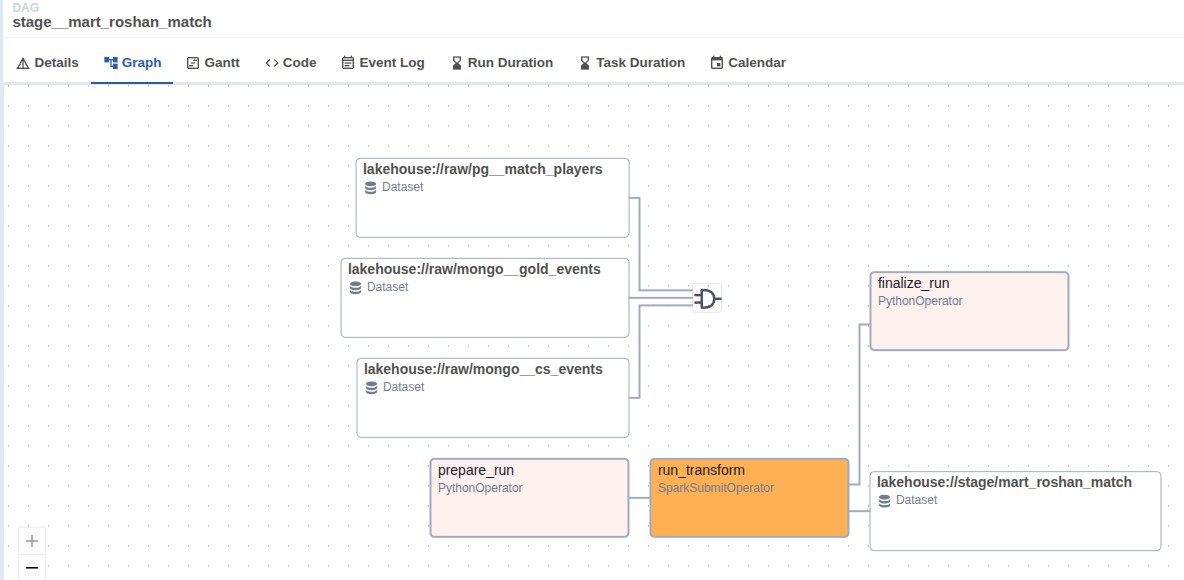

**DAG: связанные задачи Roshan**

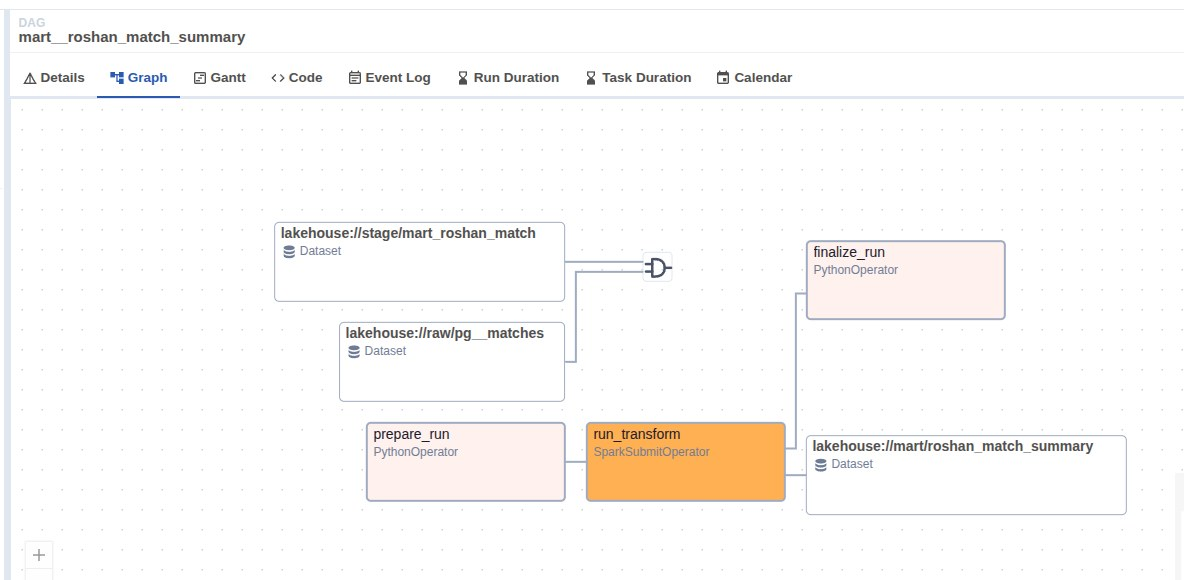


### Data Lineage — Case 03 Roshan

**Цепочка STAGE → MART**

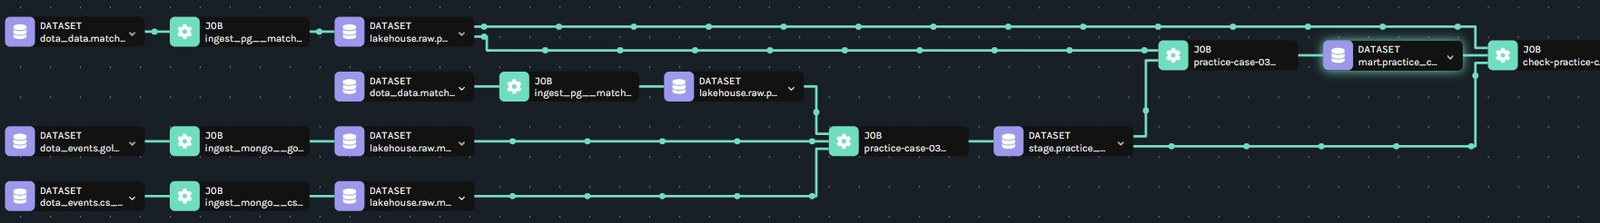

**Публикация итоговой витрины**

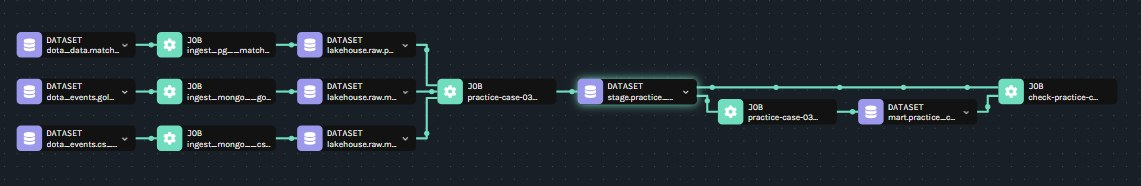


### Инженерная реализация и качество данных Roshan

- Источники: PostgreSQL `matches`, `match_players`, `npcs`; MongoDB `cs_events`, `gold_events`.
- Для Roshan выбран `npc_id = 133` (`npc_dota_roshan`). В `cs_events` обнаружено 284 233 строки, 202 311 матчей и 284 232 уникальных события. В `gold_events` — 1 939 764 строки и 342 253 уникальных события; одна выплата не равна одному убийству.
- Пересечение матчей `cs_events` и `gold_events` — 201 503. Для определения стороны используется последовательность `cs → gold`; если игрок не сопоставлен, сохраняется категория `unknown`.
- Гранулярность STAGE — одно убийство Рошана (`match_id + roshan_sec`); гранулярность MART — одна строка на матч (`match_id`).
- В MART рассчитываются `roshan_count`, `first_roshan_sec`, `radiant_kills`, `dire_kills` и `control_share = radiant_kills / roshan_count`.
- Проверки качества из отчёта: уникальность ключей STAGE и MART, равенство суммы убийств сторон общему числу Roshan, диапазон `control_share` [0;1], отсутствие NULL в ключевых полях и отсутствие Roshan после окончания матча — все проверки отмечены как PASS.

В сохранённом исследовательском выполнении team-match STAGE `lakehouse.stage.practice_case_bootcamp_roshan_team_match` не была найдена. Фактическая опубликованная MART `lakehouse.mart.roshan_match_summary` доступна; её схема и пример строк приведены ниже.

### 9.1. Проверка team-match STAGE

Проверяется отдельная STAGE-таблица с гранулярностью «матч × команда». В сохранённом выполнении она отсутствовала, поэтому условные проверки этого объекта не формируют аналитические результаты. Основные числовые выводы Roshan в этом ноутбуке приведены по опубликованной MART и зафиксированному отчёту команды.

### Проверка структуры team-match STAGE

In [11]:
ROSHAN_STAGE = "lakehouse.stage.practice_case_bootcamp_roshan_team_match"

if ROSHAN_STAGE not in available_names:
    print(
        f"Таблица {ROSHAN_STAGE} не найдена. "
        "Roshan team-match STAGE отсутствует в сохранённом снимке каталога."
    )
    roshan_ready = False
else:
    roshan_ready = True
    roshan_schema = query_df(f"DESCRIBE {ROSHAN_STAGE}")
    roshan_columns = (
        roshan_schema["Column"].tolist()
        if "Column" in roshan_schema.columns
        else roshan_schema.iloc[:, 0].tolist()
    )
    print("Колонки:", roshan_columns)
    required_roshan = {
        "match_id", "is_radiant", "radiant_win", "won",
        "roshan_count", "first_roshan_time",
    }
    missing_roshan = required_roshan - set(roshan_columns)
    if missing_roshan:
        raise ValueError(f"В Roshan STAGE отсутствуют колонки: {sorted(missing_roshan)}")

    roshan_quality = query_df(f"""
        SELECT
            COUNT(*) AS rows_count,
            COUNT(DISTINCT match_id) AS distinct_matches,
            COUNT(DISTINCT CONCAT(CAST(match_id AS VARCHAR), ':', CAST(is_radiant AS VARCHAR))) AS distinct_match_team_pairs,
            COUNT_IF(match_id IS NULL) AS null_match_id,
            COUNT_IF(is_radiant IS NULL) AS null_team,
            COUNT_IF(radiant_win IS NULL) AS null_radiant_win,
            COUNT_IF(won IS NULL) AS null_won,
            COUNT_IF(roshan_count IS NULL) AS null_roshan_count,
            COUNT_IF(roshan_count < 0) AS negative_roshan_count,
            COUNT_IF(first_roshan_time < 0) AS negative_first_roshan_time
        FROM {ROSHAN_STAGE}
    """)
    display(roshan_quality)

    q = roshan_quality.iloc[0]
    if q["null_match_id"] or q["null_team"] or q["null_won"] or q["null_roshan_count"] or q["negative_roshan_count"] or q["negative_first_roshan_time"]:
        raise ValueError("Roshan STAGE не прошла базовые проверки качества.")
    if q["rows_count"] != q["distinct_match_team_pairs"]:
        raise ValueError("Нарушена уникальность пары (match_id, is_radiant).")

Таблица lakehouse.stage.practice_case_bootcamp_roshan_team_match не найдена. Сначала опубликуй Roshan STAGE в LHlakehouse Portal.


### 9.2. Проверки гранулярности и семантики `won`

In [12]:
if roshan_ready:
    display(query_df(f"""
        SELECT
            is_radiant,
            radiant_win,
            won,
            COUNT(*) AS rows_count,
            COUNT_IF(
                (is_radiant AND won <> radiant_win)
                OR (NOT is_radiant AND won = radiant_win)
            ) AS label_conflicts
        FROM {ROSHAN_STAGE}
        GROUP BY 1, 2, 3
        ORDER BY 1, 2, 3
    """))

    roshan_grain = query_df(f"""
        SELECT
            COUNT(*) AS rows_count,
            COUNT(DISTINCT match_id) AS matches,
            COUNT_IF(is_radiant) AS radiant_rows,
            COUNT_IF(NOT is_radiant) AS dire_rows,
            COUNT_IF(roshan_count = 0) AS team_match_rows_without_roshan
        FROM {ROSHAN_STAGE}
    """)
    display(roshan_grain)

### 9.3. Win rate по количеству Roshan и времени первого Roshan

In [13]:
if roshan_ready:
    roshan_count_result = query_df(f"""
        SELECT
            CASE
                WHEN roshan_count = 0 THEN '0'
                WHEN roshan_count = 1 THEN '1'
                WHEN roshan_count = 2 THEN '2'
                ELSE '3+'
            END AS roshan_group,
            CASE WHEN is_radiant THEN 'Radiant' ELSE 'Dire' END AS team,
            COUNT(*) AS team_match_rows,
            SUM(CASE WHEN won THEN 1 ELSE 0 END) AS wins,
            AVG(CASE WHEN won THEN 1.0 ELSE 0.0 END) AS win_rate
        FROM {ROSHAN_STAGE}
        GROUP BY 1, 2
    """)
    display(roshan_count_result)

    roshan_time_result = query_df(f"""
        SELECT
            CASE
                WHEN first_roshan_time IS NULL THEN 'No recorded Roshan'
                WHEN first_roshan_time < 900 THEN '0-15 min'
                WHEN first_roshan_time < 1500 THEN '15-25 min'
                ELSE '25+ min'
            END AS first_roshan_bucket,
            CASE WHEN is_radiant THEN 'Radiant' ELSE 'Dire' END AS team,
            COUNT(*) AS team_match_rows,
            SUM(CASE WHEN won THEN 1 ELSE 0 END) AS wins,
            AVG(CASE WHEN won THEN 1.0 ELSE 0.0 END) AS win_rate
        FROM {ROSHAN_STAGE}
        GROUP BY 1, 2
    """)
    display(roshan_time_result)

### 9.4. 95% доверительные интервалы Уилсона

In [14]:
if roshan_ready:
    import math

    def wilson_interval(successes, total, z=1.959963984540054):
        if total <= 0:
            return (np.nan, np.nan)
        p = successes / total
        denom = 1 + z*z/total
        center = (p + z*z/(2*total)) / denom
        half = z * math.sqrt((p*(1-p)/total) + (z*z/(4*total*total))) / denom
        return center - half, center + half

    roshan_ci_rows = []
    for result_df, group_col, dimension in [
        (roshan_count_result, "roshan_group", "roshan_count"),
        (roshan_time_result, "first_roshan_bucket", "first_roshan_time"),
    ]:
        for row in result_df.to_dict("records"):
            low, high = wilson_interval(int(row["wins"]), int(row["team_match_rows"]))
            roshan_ci_rows.append({
                "dimension": dimension,
                "group": row[group_col],
                "team": row["team"],
                "n": int(row["team_match_rows"]),
                "wins": int(row["wins"]),
                "win_rate_pct": 100 * float(row["win_rate"]),
                "ci95_low_pct": 100 * low,
                "ci95_high_pct": 100 * high,
            })

    roshan_report = pd.DataFrame(roshan_ci_rows)
    display(roshan_report)

### 9.5. Визуализация и интерпретация team-match STAGE

In [15]:
if roshan_ready:
    for dimension, group_col, title in [
        ("roshan_count", "group", "Win rate by Roshan count"),
        ("first_roshan_time", "group", "Win rate by first Roshan timing"),
    ]:
        plot_data = roshan_report[roshan_report["dimension"] == dimension]
        if not plot_data.empty:
            pivot = plot_data.pivot(index=group_col, columns="team", values="win_rate_pct")
            ax = pivot.plot(kind="bar", figsize=(10, 4), ylim=(0, 100))
            ax.set_title(title)
            ax.set_ylabel("Win rate, %")
            ax.set_xlabel("Group")
            plt.xticks(rotation=25)
            plt.tight_layout()
            plt.show()

    print("Интерпретируй вместе: win rate, n и ширину 95% CI.")
    print("Не делай причинный вывод о том, что Roshan сам по себе повышает вероятность победы.")

### 9.6. Сводный Dashboard Roshan в ноутбуке

In [16]:
if roshan_ready and "roshan_report" in globals():
    import matplotlib.pyplot as plt

    roshan_total_matches = int(roshan_grain.iloc[0]["matches"])
    roshan_radiant_rows = query_df(f"""
        SELECT
            COUNT(*) AS matches,
            SUM(CASE WHEN won THEN 1 ELSE 0 END) AS wins
        FROM {ROSHAN_STAGE}
        WHERE is_radiant
    """)
    roshan_overall_rate = (
        float(roshan_radiant_rows.iloc[0]["wins"]) /
        float(roshan_radiant_rows.iloc[0]["matches"])
        if float(roshan_radiant_rows.iloc[0]["matches"]) > 0 else np.nan
    )

    fig, axes = plt.subplots(2, 3, figsize=(19, 10))
    fig.suptitle("Case 03 — Roshan | Business Dashboard", fontsize=17, y=1.02)

    # 1. KPI: Radiant overall win rate.
    ax = axes[0, 0]
    ax.axis("off")
    ax.text(0.03, 0.86, "RADIANT WIN RATE", fontsize=11, transform=ax.transAxes)
    ax.text(0.03, 0.50, f"{roshan_overall_rate:.4f}",
            fontsize=34, fontweight="bold", transform=ax.transAxes)
    ax.text(0.03, 0.22, f"Matches represented: {roshan_total_matches:,}",
            fontsize=12, transform=ax.transAxes)
    ax.text(0.03, 0.08, "Descriptive KPI; not causal effect",
            fontsize=10, transform=ax.transAxes)

    # 2. Number of team-match observations by Roshan count.
    ax = axes[0, 1]
    count_totals = (
        roshan_count_result.groupby("roshan_group", as_index=False)["team_match_rows"].sum()
    )
    ax.bar(count_totals["roshan_group"].astype(str), count_totals["team_match_rows"])
    ax.set_title("Observations by Roshan count")
    ax.set_xlabel("Roshan kills per match/team")
    ax.set_ylabel("Team-match rows")

    # 3. Win rate by Roshan count, split by team.
    ax = axes[0, 2]
    count_pivot = roshan_count_result.pivot(
        index="roshan_group", columns="team", values="win_rate"
    ) * 100
    count_pivot.plot(kind="bar", ax=ax)
    ax.set_title("Win rate by Roshan count")
    ax.set_ylabel("Win rate, %")
    ax.set_xlabel("Roshan count")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=0)

    # 4. Win rate by first Roshan timing, split by team.
    ax = axes[1, 0]
    time_pivot = roshan_time_result.pivot(
        index="first_roshan_bucket", columns="team", values="win_rate"
    ) * 100
    time_pivot.plot(kind="bar", ax=ax)
    ax.set_title("Win rate by first Roshan timing")
    ax.set_ylabel("Win rate, %")
    ax.set_xlabel("First Roshan time")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=25)

    # 5. Radiant vs Dire overall win rate.
    ax = axes[1, 1]
    team_summary = (
        roshan_report[roshan_report["dimension"] == "roshan_count"]
        .groupby("team", as_index=False)
        .agg(wins=("wins", "sum"), n=("n", "sum"))
    )
    team_summary["win_rate_pct"] = 100 * team_summary["wins"] / team_summary["n"]
    ax.bar(team_summary["team"], team_summary["win_rate_pct"])
    ax.set_title("Overall win rate by team")
    ax.set_ylabel("Win rate, %")
    ax.set_ylim(0, 100)

    # 6. Confidence intervals for Roshan-count groups.
    ax = axes[1, 2]
    ci_plot = roshan_report[roshan_report["dimension"] == "roshan_count"].copy()
    ci_plot["label"] = ci_plot["group"].astype(str) + " / " + ci_plot["team"].astype(str)
    ci_plot = ci_plot.sort_values(["group", "team"])
    x = np.arange(len(ci_plot))
    y = ci_plot["win_rate_pct"].to_numpy()
    lower = y - ci_plot["ci95_low_pct"].to_numpy()
    upper = ci_plot["ci95_high_pct"].to_numpy() - y
    ax.errorbar(x, y, yerr=[lower, upper], fmt="o", capsize=3)
    ax.set_xticks(x, ci_plot["label"], rotation=35, ha="right")
    ax.set_title("Win rate with 95% Wilson CI")
    ax.set_ylabel("Win rate, %")
    ax.set_ylim(0, 100)

    fig.tight_layout()
    plt.show()
else:
    print("Roshan dashboard пропущен: Roshan STAGE или аналитические результаты недоступны.")

Roshan dashboard пропущен: Roshan STAGE или аналитические результаты недоступны.


### 9.7. Проверка фактической Roshan MART

In [17]:
# Проверяем структуру опубликованной Roshan MART

ROSHAN_MART = "lakehouse.mart.roshan_match_summary"

try:
    roshan_schema = query_df(f"DESCRIBE {ROSHAN_MART}")

    print(f"Таблица: {ROSHAN_MART}")
    print("\nСтруктура таблицы:")
    display(roshan_schema)

    print("\nПервые 5 строк:")
    roshan_sample = query_df(f"""
        SELECT *
        FROM {ROSHAN_MART}
        LIMIT 5
    """)
    display(roshan_sample)

except Exception as e:
    print(f"Ошибка при проверке Roshan MART: {e}")

Таблица: lakehouse.mart.roshan_match_summary

Структура таблицы:


,Column,Type,Extra,Comment
0,match_id,bigint,,Уникальный ID матча (Valve)
1,duration,integer,,Длительность (сек)
2,radiant_win,integer,,true если Radiant победил
3,game_mode,integer,,ID режима игры
4,roshan_count,bigint,,Убийств Рошана в матче (0 — не было)
5,first_roshan_sec,integer,,"Время первого убийства Рошана, сек"
6,first_roshan_radiant,integer,,"1 — первого Рошана забрал Radiant, 0 — Dire"
7,radiant_kills,bigint,,Рошанов забрал Radiant
8,dire_kills,bigint,,Рошанов забрал Dire
9,control_share,double,,Доля Рошанов у Radiant (0…1)



Первые 5 строк:


,match_id,duration,radiant_win,game_mode,roshan_count,first_roshan_sec,first_roshan_radiant,radiant_kills,dire_kills,control_share
0,9044657999,2594,1,22,2,1669.0,1.0,2.0,0.0,1.0
1,9044709591,1022,1,23,0,NaN,NaN,NaN,NaN,NaN
2,9044706638,1128,1,23,0,NaN,NaN,NaN,NaN,NaN
3,9044705933,1206,0,23,0,NaN,NaN,NaN,NaN,NaN
4,9044683780,1930,0,23,1,1346.0,0.0,0.0,1.0,0.0


In [ ]:
# Дополнительные проверки гипотез на опубликованной MART.
# Ячейка использует только SELECT и не изменяет таблицы Lakehouse.
ROSHAN_MART = "lakehouse.mart.roshan_match_summary"

roshan_hypothesis_queries = {
    "R1 — первый Roshan и исход матча": f"""
        SELECT
            CASE
                WHEN roshan_count = 0 THEN 'No Roshan'
                WHEN first_roshan_radiant = 1 THEN 'First Roshan: Radiant'
                WHEN first_roshan_radiant = 0 THEN 'First Roshan: Dire'
                ELSE 'Unknown side'
            END AS first_roshan_group,
            COUNT(*) AS matches,
            AVG(CAST(radiant_win AS DOUBLE)) * 100 AS radiant_win_rate_pct
        FROM {ROSHAN_MART}
        GROUP BY 1
        ORDER BY 1
    """,
    "R3 — число Roshan у Radiant": f"""
        SELECT
            CASE
                WHEN radiant_kills = 0 THEN '0'
                WHEN radiant_kills = 1 THEN '1'
                WHEN radiant_kills = 2 THEN '2'
                WHEN radiant_kills = 3 THEN '3'
                ELSE '4+'
            END AS radiant_roshan_kills,
            COUNT(*) AS matches,
            AVG(CAST(radiant_win AS DOUBLE)) * 100 AS radiant_win_rate_pct
        FROM {ROSHAN_MART}
        GROUP BY 1
        ORDER BY 1
    """,
    "R4 — первый Roshan и длительность матча": f"""
        SELECT
            CASE
                WHEN duration < 1200 THEN '10-19 min'
                WHEN duration < 1800 THEN '20-29 min'
                WHEN duration < 2400 THEN '30-39 min'
                WHEN duration < 3000 THEN '40-49 min'
                WHEN duration < 3600 THEN '50-59 min'
                WHEN duration < 4200 THEN '60-69 min'
                ELSE '70+ min'
            END AS match_duration_group,
            COUNT(*) AS matches,
            AVG(
                CASE
                    WHEN first_roshan_radiant = 1 THEN CAST(radiant_win AS DOUBLE)
                    ELSE 1.0 - CAST(radiant_win AS DOUBLE)
                END
            ) * 100 AS first_roshan_team_win_rate_pct,
            AVG(
                CASE
                    WHEN first_roshan_radiant = 1 THEN 1.0 - CAST(radiant_win AS DOUBLE)
                    ELSE CAST(radiant_win AS DOUBLE)
                END
            ) * 100 AS opponent_win_rate_pct
        FROM {ROSHAN_MART}
        WHERE roshan_count > 0 AND first_roshan_radiant IS NOT NULL
        GROUP BY 1
        ORDER BY 1
    """,
    "H2b — доля контроля Radiant": f"""
        SELECT
            CASE
                WHEN control_share = 0 THEN '0%'
                WHEN control_share < 0.50 THEN '1-49%'
                WHEN control_share < 0.75 THEN '50-74%'
                WHEN control_share < 1 THEN '75-99%'
                WHEN control_share = 1 THEN '100%'
            END AS control_share_group,
            COUNT(*) AS matches,
            AVG(CAST(radiant_win AS DOUBLE)) * 100 AS radiant_win_rate_pct
        FROM {ROSHAN_MART}
        WHERE roshan_count > 0 AND control_share IS NOT NULL
        GROUP BY 1
        ORDER BY 1
    """,
}

for hypothesis, sql in roshan_hypothesis_queries.items():
    print(hypothesis)
    display(query_df(sql))

### Superset Dashboard — Case 03 Roshan

**Сводные KPI и win rate по группам**

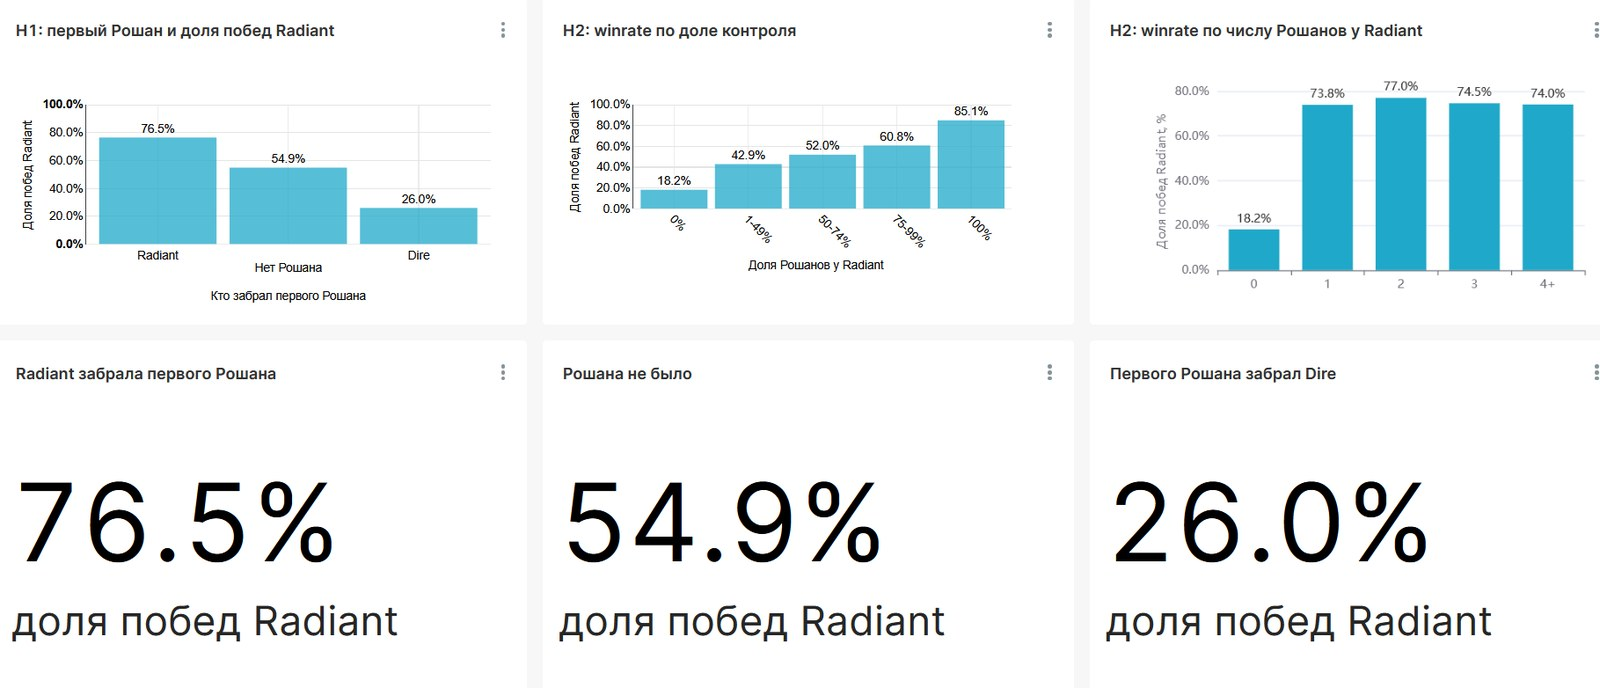

**Динамика показателей и объём выборки**

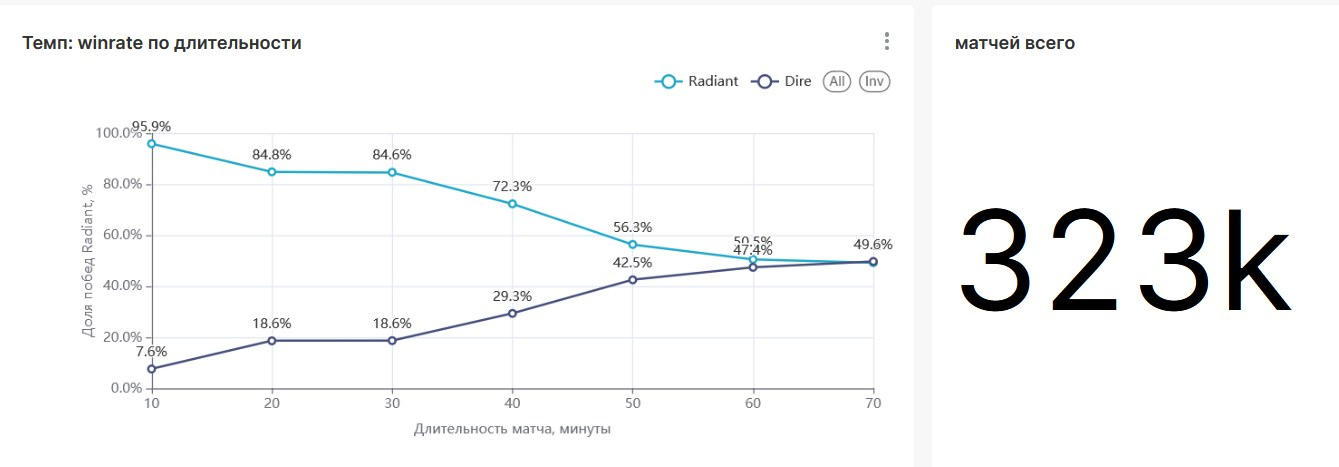


## 10. Кейс №16 Winner — прогноз победителя по первым 15 минутам

**Аналитический вопрос:** можно ли предсказать победителя матча, используя только информацию, доступную к 15-й минуте?

### Гипотезы и результаты

| ID | Гипотеза / критерий | Результат | Вывод |
|---|---|---|---|
| **W1** | Преимущество Radiant по золоту более 5 000 к 15-й минуте связано с win rate не ниже 70% | Win rate Radiant монотонно растёт от **16,2%** при дефиците более 5 000 до **87,1%** при преимуществе более 5 000. Промежуточные группы: 33,4%; 45,4%; 55,9%; 69,8%. | **Подтверждена.** Золото — сильный ранний индикатор преимущества. |
| **W2** | Верхняя и нижняя трети по числу убийств различаются по win rate не менее чем на 5 п.п. | Медиана `kill_events_15m` одинакова для побед Radiant и Dire — 27; Spearman ρ = −0,0059, p = 0,502. | **Не подтверждена** на доступной выборке. |
| **W3** | Ранняя и поздняя первая кровь различаются по win rate не менее чем на 5 п.п. | Медиана `first_blood_time_15m` в группах побед Radiant и Dire — 57 секунд; ρ = −0,0013, p = 0,879. | **Не подтверждена** на доступной выборке. |
| **W4** | Верхняя и нижняя трети по урону башням различаются по win rate не менее чем на 5 п.п. | Медиана `tower_damage_15m`: 2 403 у побед Radiant и 2 381,5 у побед Dire; ρ = 0,00045, p = 0,959. | **Не подтверждена** на доступной выборке. |
| **W5** | Модель превосходит majority baseline; целевые уровни ROC-AUC ≥ 0,70 и balanced accuracy ≥ 60% | На holdout из 2 621 матча Random Forest: Accuracy **72,99%**, Balanced Accuracy **73,16%**, F1 **73,30%**, ROC-AUC **81,20%**. Dummy baseline: Accuracy **52,84%**, Balanced Accuracy **50,00%**. | **Предварительно подтверждена.** Для применения нужна временная валидация и проверка калибровки. |

Результаты W1–W5 перенесены из презентации и исходного `Case16_Winner.ipynb`: выборка — **13 101 матч**, holdout — **2 621 матч**. В объединённом ноутбуке ячейки Winner не имели сохранённых outputs; их код сохранён без выполнения. В исходном коде `WINNER_MART` задана как `lakehouse.mart.case16_winner_dataset`, тогда как на слайде и в общем перечне целевых таблиц указано `lakehouse.mart.practice_case_16_winner_dataset`; фактическое имя по сохранённому выполнению не подтверждено.

### Airflow DAG — Case 16 Winner

**DAG: поток задач Winner, часть 1**

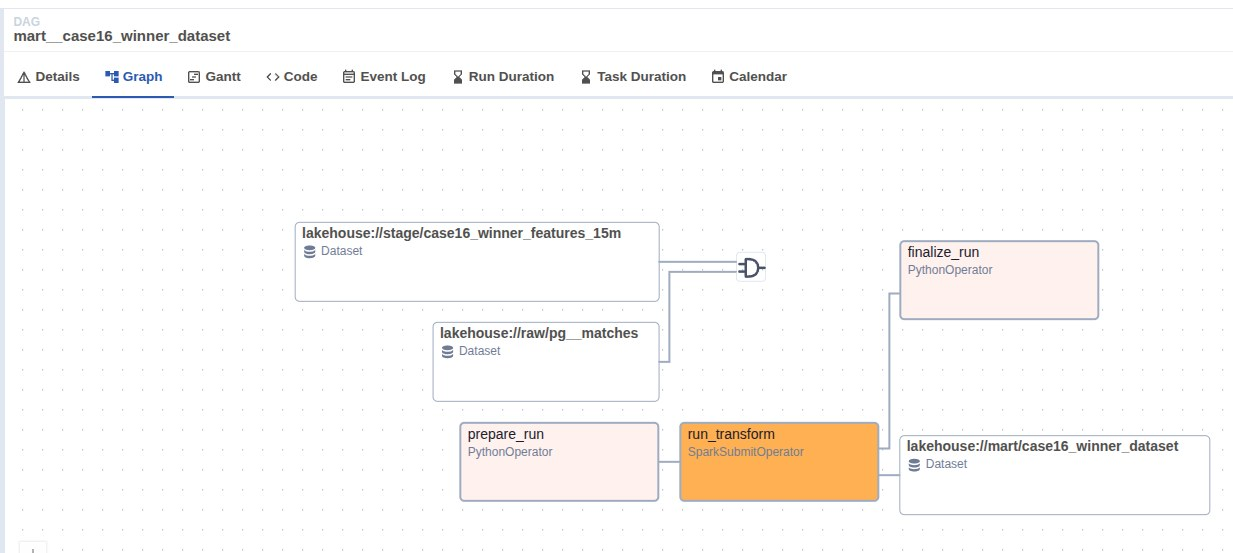

**DAG: поток задач Winner, часть 2**

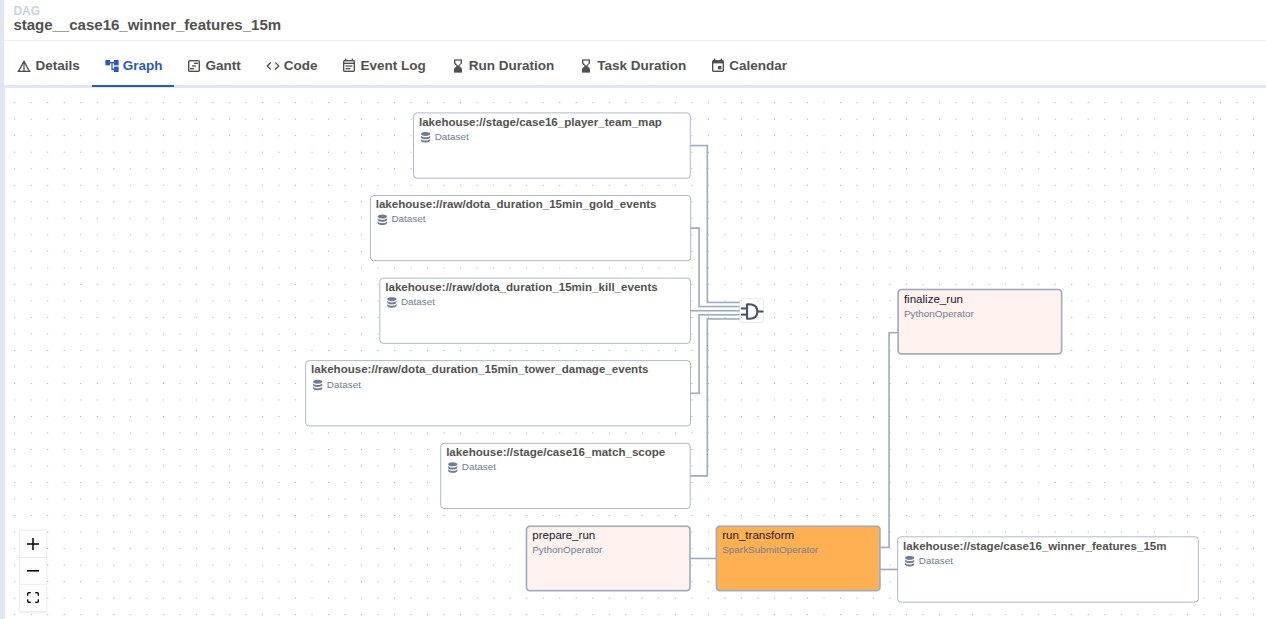

**DAG: поток задач Winner, часть 3**

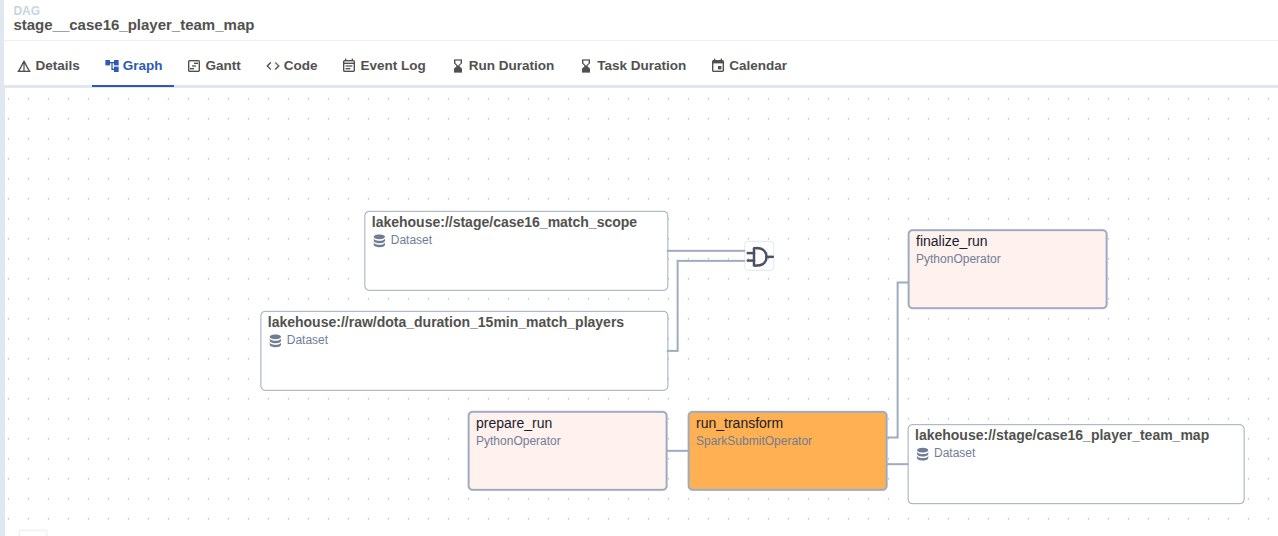

**DAG: поток задач Winner, часть 4**

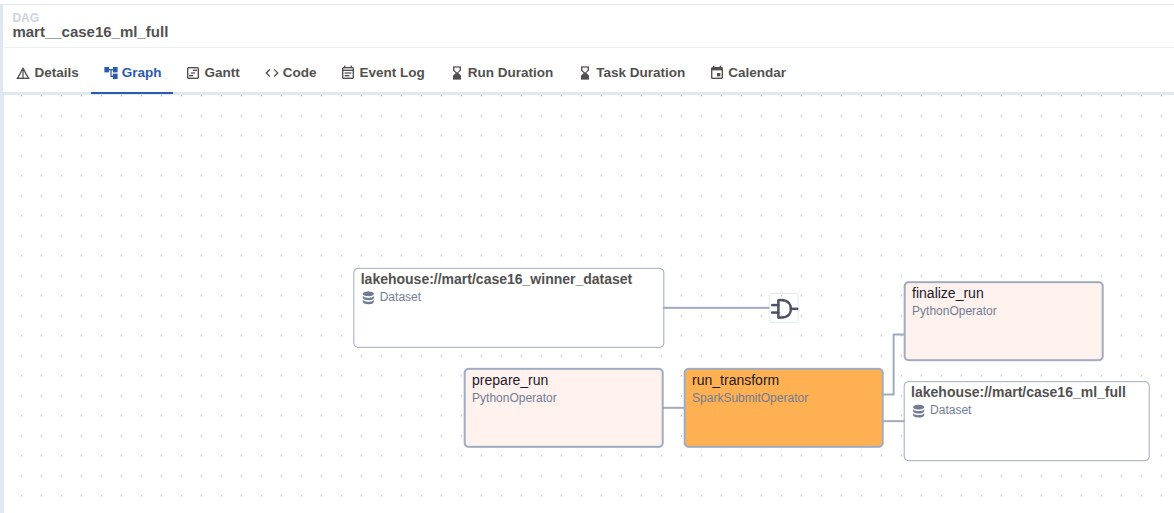


### Data Lineage — Case 16 Winner

**Зависимости источников, STAGE и MART**

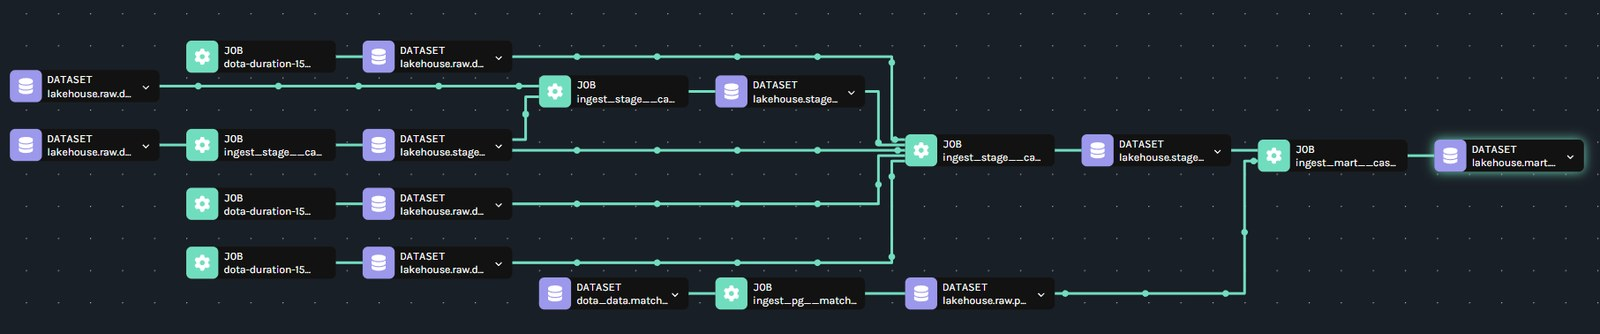


In [ ]:
!pip -q install scikit-learn joblib

### 10.1. Параметры эксперимента и проверка MART

В отличие от отдельного исходного ноутбука, подключение Trino повторно не создаём: используем `conn`, `cursor` и `query_df` из предыдущих разделов.

In [ ]:
import json
import warnings
from pathlib import Path

import joblib
import numpy as np
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

WINNER_MART = "lakehouse.mart.case16_winner_dataset"
BATCH_SIZE = 5000
TEST_SIZE = 0.20
RANDOM_STATE = 42

CANDIDATE_FEATURES = [
    "game_mode",
    "first_blood_time_15m",
    "radiant_gold_15m",
    "dire_gold_15m",
    "gold_diff_15m",
    "radiant_gold_event_count_15m",
    "dire_gold_event_count_15m",
    "kill_events_15m",
    "tower_damage_15m",
    "tower_damage_event_count_15m",
]

ARTIFACT_DIR = Path("case16_artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

if WINNER_MART not in available_names:
    print(
        f"Витрина {WINNER_MART} пока не найдена. "
        "MART отсутствует в доступном каталоге; блок анализа пропущен. "
        "Статус доступности отражён в инвентаризации Lakehouse."
    )
    winner_mart_ready = False
else:
    winner_mart_ready = True
    winner_columns_df = query_df(f"DESCRIBE {WINNER_MART}")
    mart_columns = winner_columns_df["Column"].tolist() if "Column" in winner_columns_df.columns else winner_columns_df.iloc[:, 0].tolist()
    print("MART:", WINNER_MART)
    print("Колонки:", mart_columns)

    required_columns = {"match_id", "radiant_win"}
    missing_required = required_columns - set(mart_columns)
    if missing_required:
        raise ValueError(f"В MART отсутствуют обязательные колонки: {sorted(missing_required)}")

    winner_features = [col for col in CANDIDATE_FEATURES if col in mart_columns]
    if not winner_features:
        raise ValueError(
            "В MART не найдены ожидаемые признаки. Сверь реальные имена столбцов "
            "с контрактом MART в LHlakehouse Portal."
        )
    print("Найденные признаки:", winner_features)

### 10.2. Загрузка MART

Загружаем только `match_id`, target и признаки, которые действительно присутствуют в витрине. Используем пакетную загрузку, чтобы не запрашивать весь результат одним fetch.

In [ ]:
if winner_mart_ready:
    selected_columns = ["match_id", "radiant_win"] + winner_features
    quoted_columns = ", ".join(f'"{col}"' for col in selected_columns)
    winner_sql = f"SELECT {quoted_columns} FROM {WINNER_MART}"

    winner_cursor = conn.cursor()
    winner_chunks = []
    try:
        winner_cursor.execute(winner_sql)
        while True:
            rows = winner_cursor.fetchmany(BATCH_SIZE)
            if not rows:
                break
            winner_chunks.append(pd.DataFrame(rows, columns=selected_columns))
    finally:
        winner_cursor.close()

    winner_df = (
        pd.concat(winner_chunks, ignore_index=True)
        if winner_chunks
        else pd.DataFrame(columns=selected_columns)
    )

    print("Загружено строк:", len(winner_df))
    display(winner_df.head())

    if winner_df.empty:
        raise ValueError("MART существует, но не содержит строк.")

### 10.3. Проверка качества и подготовка target

Ожидается одна строка на матч. Дубликаты не удаляем автоматически: они могут указывать на ошибку JOIN или агрегации в ETL.

In [ ]:
if winner_mart_ready:
    duplicate_count = int(winner_df["match_id"].duplicated().sum())
    print("Дубликаты match_id:", duplicate_count)
    if duplicate_count:
        raise ValueError(
            "В MART больше одной строки на match_id. Исправь агрегацию/JOIN "
            "в процессе платформы, а не удаляй дубликаты здесь автоматически."
        )

    def normalize_winner_label(value):
        if pd.isna(value):
            return np.nan
        if isinstance(value, (bool, np.bool_)):
            return int(value)
        if isinstance(value, (int, np.integer, float, np.floating)):
            if value == 1:
                return 1
            if value == 0:
                return 0
        normalized = str(value).strip().lower()
        if normalized in {"true", "1", "radiant", "radiant_win"}:
            return 1
        if normalized in {"false", "0", "dire", "dire_win"}:
            return 0
        return np.nan

    winner_y_all = winner_df["radiant_win"].map(normalize_winner_label)
    valid_labels = winner_y_all.notna()
    removed_labels = int((~valid_labels).sum())
    print("Строк с пустой/непонятной меткой исключено:", removed_labels)

    winner_df = winner_df.loc[valid_labels].reset_index(drop=True)
    winner_y = winner_y_all.loc[valid_labels].astype("int64").reset_index(drop=True)

    if len(winner_df) < 20:
        raise ValueError(f"Слишком мало размеченных матчей: {len(winner_df)}; требуется минимум 20.")

    class_counts = winner_y.value_counts().sort_index()
    print("Распределение метки (0 = победа Dire, 1 = победа Radiant):")
    display(class_counts.rename_axis("radiant_win").to_frame("matches"))

    if winner_y.nunique() != 2 or class_counts.min() < 2:
        raise ValueError("Для stratified train/test split нужны оба класса и минимум по два наблюдения в каждом.")

In [ ]:
# W1: проверка win rate Radiant по диапазонам gold_diff_15m.
# Положительная разница означает преимущество Radiant только если
# семантика поля в MART именно radiant_gold - dire_gold.

if (
    "winner_mart_ready" in globals()
    and winner_mart_ready
    and "winner_df" in globals()
    and "gold_diff_15m" in winner_df.columns
):
    gold_hypothesis_df = pd.DataFrame({
        "gold_diff_15m": pd.to_numeric(winner_df["gold_diff_15m"], errors="coerce"),
        "radiant_win": winner_y,
    }).dropna()

    gold_hypothesis_df["gold_bucket"] = pd.cut(
        gold_hypothesis_df["gold_diff_15m"],
        bins=[-np.inf, -5000, -2000, 0, 2000, 5000, np.inf],
        labels=["Radiant -5000+", "Radiant -2000..-5000", "Radiant behind", "Radiant +0..2000", "Radiant +2000..5000", "Radiant +5000+"],
    )

    gold_winrate = (
        gold_hypothesis_df.groupby("gold_bucket", observed=False)
        .agg(
            matches=("radiant_win", "size"),
            radiant_wins=("radiant_win", "sum"),
            radiant_win_rate=("radiant_win", "mean"),
            median_gold_diff=("gold_diff_15m", "median"),
        )
        .reset_index()
    )
    display(gold_winrate)

    ax = gold_winrate.plot(
        kind="bar", x="gold_bucket", y="radiant_win_rate",
        figsize=(10, 4), ylim=(0, 1), legend=False,
        title="Case 16: Radiant win rate by gold difference at 15 minutes"
    )
    ax.set_ylabel("Radiant win rate")
    ax.set_xlabel("Gold difference bucket")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Нет gold_diff_15m в Winner MART — W1 нельзя проверить.")

### 10.4. Признаки и контроль утечки target

`match_id` используется только для контроля уникальности. `radiant_win` — целевая переменная. В признаки допускаются только данные, доступные к 15-й минуте. Итоговая длительность матча, финальный счёт и другие постматчевые данные использовать нельзя.

In [ ]:
if winner_mart_ready:
    X_winner = winner_df[winner_features].copy()
    for col in X_winner.columns:
        X_winner[col] = pd.to_numeric(X_winner[col], errors="coerce")

    all_null_features = [col for col in X_winner.columns if X_winner[col].notna().sum() == 0]
    if all_null_features:
        warnings.warn(f"Исключены полностью пустые признаки: {all_null_features}")
        X_winner = X_winner.drop(columns=all_null_features)

    if X_winner.shape[1] == 0:
        raise ValueError("После проверки не осталось числовых признаков.")

    winner_features_final = list(X_winner.columns)
    print("Итоговые признаки:", winner_features_final)
    display(X_winner.describe().T)
    print("Доля пропусков:")
    display(X_winner.isna().mean().sort_values(ascending=False).to_frame("missing_share"))

In [ ]:
# W2-W4: описательная аналитика и непараметрические сравнения.
# Для каждой числовой фичи считаем медианы/квантили по классам,
# Mann-Whitney U и ранговую корреляцию Spearman.
# Это ассоциации, а не причинные эффекты.

if "winner_mart_ready" in globals() and winner_mart_ready and "X_winner" in globals():
    from scipy.stats import mannwhitneyu, spearmanr

    winner_business_rows = []
    for feature in X_winner.columns:
        tmp = pd.DataFrame({
            "feature_value": pd.to_numeric(X_winner[feature], errors="coerce"),
            "radiant_win": winner_y,
        }).dropna()

        radiant_values = tmp.loc[tmp["radiant_win"] == 1, "feature_value"]
        dire_values = tmp.loc[tmp["radiant_win"] == 0, "feature_value"]

        if len(radiant_values) < 2 or len(dire_values) < 2 or tmp["feature_value"].nunique() < 2:
            continue

        test = mannwhitneyu(radiant_values, dire_values, alternative="two-sided")
        rho, rho_p = spearmanr(tmp["feature_value"], tmp["radiant_win"])

        winner_business_rows.append({
            "feature": feature,
            "n_radiant_wins": len(radiant_values),
            "n_dire_wins": len(dire_values),
            "median_radiant_win": radiant_values.median(),
            "median_dire_win": dire_values.median(),
            "median_difference": radiant_values.median() - dire_values.median(),
            "spearman_rho": rho,
            "spearman_p": rho_p,
            "mann_whitney_p": test.pvalue,
        })

    winner_business_analysis = pd.DataFrame(winner_business_rows)
    if not winner_business_analysis.empty:
        display(winner_business_analysis.sort_values("mann_whitney_p"))
    else:
        print("Недостаточно вариативности/наблюдений для статистических сравнений.")
else:
    print("Winner MART не загружена — аналитика гипотез W1-W4 пропущена.")

### 10.5. Train/test split и baseline

В качестве простого baseline оценивается DummyClassifier, который всегда предсказывает наиболее частый класс. Это минимальная точка сравнения для Random Forest.

In [ ]:
if winner_mart_ready:
    X_train, X_test, y_train, y_test = train_test_split(
        X_winner,
        winner_y,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
        stratify=winner_y,
    )

    dummy = DummyClassifier(strategy="most_frequent")
    dummy.fit(X_train, y_train)
    dummy_pred = dummy.predict(X_test)

    dummy_metrics = {
        "accuracy": float(accuracy_score(y_test, dummy_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_test, dummy_pred)),
    }
    print("Dummy baseline:")
    print(json.dumps(dummy_metrics, ensure_ascii=False, indent=2))

### 10.6. Random Forest и оценка качества

Модель использует медианное заполнение пропусков и Random Forest. Метрики считаются на отложенной тестовой выборке.

In [ ]:
if winner_mart_ready:
    winner_model = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            max_depth=10,
            min_samples_leaf=3,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ])

    winner_model.fit(X_train, y_train)
    winner_pred = winner_model.predict(X_test)
    winner_proba = winner_model.predict_proba(X_test)[:, 1]

    winner_metrics = {
        "accuracy": float(accuracy_score(y_test, winner_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_test, winner_pred)),
        "f1": float(f1_score(y_test, winner_pred, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_test, winner_proba)) if y_test.nunique() == 2 else None,
        "train_rows": int(len(X_train)),
        "test_rows": int(len(X_test)),
        "features": winner_features_final,
        "baseline": dummy_metrics,
        "mart_table": WINNER_MART,
    }

    print("Метрики Random Forest:")
    print(json.dumps(winner_metrics, ensure_ascii=False, indent=2))
    print("Матрица ошибок [строки = true, столбцы = predicted], классы [0, 1]:")
    display(pd.DataFrame(
        confusion_matrix(y_test, winner_pred, labels=[0, 1]),
        index=["true_Dire", "true_Radiant"],
        columns=["pred_Dire", "pred_Radiant"],
    ))
    print("Отчёт классификации:")
    print(classification_report(
        y_test,
        winner_pred,
        labels=[0, 1],
        target_names=["Dire win (0)", "Radiant win (1)"],
        zero_division=0,
    ))

### Интерпретация результатов Winner

- W1 показывает, что преимущество по золоту к 15-й минуте — наиболее сильный единичный бизнес-сигнал из проверенных гипотез.
- W2–W4 не получили поддержки в представленных статистических проверках. Небольшое различие медиан или высокая feature importance сами по себе не должны трактоваться как причинное влияние.
- W5 превосходит baseline на случайном holdout, но результат предварительный: перед использованием в live-аналитике требуются временной split, проверка калибровки вероятностей и оценка precision/recall при выбранном пороге.

### 10.7. Важность признаков

In [ ]:
if winner_mart_ready:
    rf = winner_model.named_steps["classifier"]
    winner_importance = pd.DataFrame({
        "feature": winner_features_final,
        "importance": rf.feature_importances_,
    }).sort_values("importance", ascending=False).reset_index(drop=True)

    display(winner_importance)

### 10.8. Сводный Dashboard Winner — визуализация в стиле Superset

Шесть панелей по кейсу Winner:
1. общий win rate Radiant;
2. baseline vs Random Forest;
3. важность признаков;
4. win rate по совместным диапазонам gold difference и kill events;
5. win rate по gold difference;
6. матрица ошибок.

Dashboard строится по уже загруженной MART и holdout-предсказаниям. Повторного обращения к Trino здесь нет.

In [ ]:
if winner_mart_ready:
    import matplotlib.pyplot as plt

    # Данные holdout для графиков и матрицы ошибок.
    winner_dashboard_df = pd.DataFrame({
        "radiant_win": y_test.to_numpy(),
        "predicted": winner_pred,
        "probability_radiant": winner_proba,
    }, index=X_test.index)

    if "gold_diff_15m" in X_test.columns:
        winner_dashboard_df["gold_diff_15m"] = X_test["gold_diff_15m"].to_numpy()
    if "kill_events_15m" in X_test.columns:
        winner_dashboard_df["kill_events_15m"] = X_test["kill_events_15m"].to_numpy()

    fig, axes = plt.subplots(2, 3, figsize=(19, 10))
    fig.suptitle("Case 16 — Winner | Model Dashboard", fontsize=17, y=1.02)

    # 1. Overall Radiant win rate in the complete valid MART sample.
    ax = axes[0, 0]
    radiant_win_rate = float(winner_y.mean())
    ax.axis("off")
    ax.text(0.03, 0.86, "OVERALL RADIANT WIN RATE", fontsize=11, transform=ax.transAxes)
    ax.text(0.03, 0.50, f"{radiant_win_rate:.4f}", fontsize=34,
            fontweight="bold", transform=ax.transAxes)
    ax.text(0.03, 0.22, f"Valid matches: {len(winner_y):,}",
            fontsize=12, transform=ax.transAxes)
    ax.text(0.03, 0.08, f"Holdout: {len(y_test):,}",
            fontsize=10, transform=ax.transAxes)

    # 2. Baseline vs full model.
    ax = axes[0, 1]
    winner_metric_compare = pd.DataFrame({
        "baseline": {
            "accuracy": dummy_metrics["accuracy"],
            "f1": f1_score(y_test, dummy_pred, zero_division=0),
            "roc_auc": 0.5,
        },
        "full": {
            "accuracy": winner_metrics["accuracy"],
            "f1": winner_metrics["f1"],
            "roc_auc": winner_metrics["roc_auc"],
        },
    })
    winner_metric_compare.plot(kind="bar", ax=ax)
    ax.set_title("Model metrics: baseline vs full")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(fontsize=8)

    # 3. Feature importance.
    ax = axes[0, 2]
    winner_importance_plot = winner_importance.sort_values("importance", ascending=True).tail(10)
    ax.barh(winner_importance_plot["feature"], winner_importance_plot["importance"])
    ax.set_title("Feature importance")
    ax.set_xlabel("Importance")

    # 4. Win-rate heatmap by gold difference and kill events.
    ax = axes[1, 0]
    if {"gold_diff_15m", "kill_events_15m"}.issubset(winner_dashboard_df.columns):
        heat_df = winner_dashboard_df.dropna(subset=["gold_diff_15m", "kill_events_15m"]).copy()
        if len(heat_df) >= 10:
            heat_df["gold_bucket"] = pd.qcut(
                heat_df["gold_diff_15m"], q=5, duplicates="drop"
            )
            heat_df["kills_bucket"] = pd.qcut(
                heat_df["kill_events_15m"], q=5, duplicates="drop"
            )
            heat_pivot = heat_df.pivot_table(
                index="kills_bucket", columns="gold_bucket",
                values="radiant_win", aggfunc="mean", observed=False
            )
            im = ax.imshow(heat_pivot.values, aspect="auto", vmin=0, vmax=1)
            ax.set_title("Radiant win rate: gold × kills")
            ax.set_xlabel("Gold difference quantile")
            ax.set_ylabel("Kill events quantile")
            ax.set_xticks(range(len(heat_pivot.columns)), range(1, len(heat_pivot.columns)+1))
            ax.set_yticks(range(len(heat_pivot.index)), range(1, len(heat_pivot.index)+1))
            fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Win rate")
        else:
            ax.text(0.5, 0.5, "Not enough holdout observations", ha="center", va="center")
            ax.set_axis_off()
    else:
        ax.text(0.5, 0.5, "gold_diff_15m / kill_events_15m unavailable",
                ha="center", va="center")
        ax.set_axis_off()

    # 5. Win rate by gold-difference buckets (holdout).
    ax = axes[1, 1]
    if "gold_diff_15m" in winner_dashboard_df.columns:
        gold_plot = winner_dashboard_df.dropna(subset=["gold_diff_15m"]).copy()
        if len(gold_plot) >= 10:
            gold_plot["gold_bucket"] = pd.qcut(
                gold_plot["gold_diff_15m"], q=10, duplicates="drop"
            )
            gold_curve = gold_plot.groupby("gold_bucket", observed=False).agg(
                win_rate=("radiant_win", "mean"),
                n=("radiant_win", "size"),
            ).reset_index()
            ax.plot(range(len(gold_curve)), gold_curve["win_rate"], marker="o")
            ax.set_xticks(range(len(gold_curve)), [str(x) for x in gold_curve["gold_bucket"]], rotation=35, ha="right")
            ax.set_ylim(0, 1)
            ax.set_title("Radiant win rate by gold difference")
            ax.set_ylabel("Win rate")
            ax.set_xlabel("Gold difference buckets")
        else:
            ax.text(0.5, 0.5, "Not enough observations", ha="center", va="center")
            ax.set_axis_off()
    else:
        ax.text(0.5, 0.5, "gold_diff_15m unavailable", ha="center", va="center")
        ax.set_axis_off()

    # 6. Confusion matrix.
    ax = axes[1, 2]
    winner_cm = confusion_matrix(y_test, winner_pred, labels=[0, 1])
    im = ax.imshow(winner_cm, aspect="auto")
    ax.set_title("Confusion matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_xticks([0, 1], ["Dire", "Radiant"])
    ax.set_yticks([0, 1], ["Dire", "Radiant"])
    for row in range(2):
        for col in range(2):
            ax.text(col, row, f"{winner_cm[row, col]:,}",
                    ha="center", va="center", fontsize=11)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Matches")

    fig.tight_layout()
    plt.show()

### 10.9. Superset Dashboard Winner

Дашборд показывает общий win rate Radiant, baseline vs Random Forest, важность признаков, совместные диапазоны золота и убийств, win rate по gold difference и матрицу ошибок.

### Superset Dashboard — Case 16 Winner

**Итоговая панель прогноза победителя**

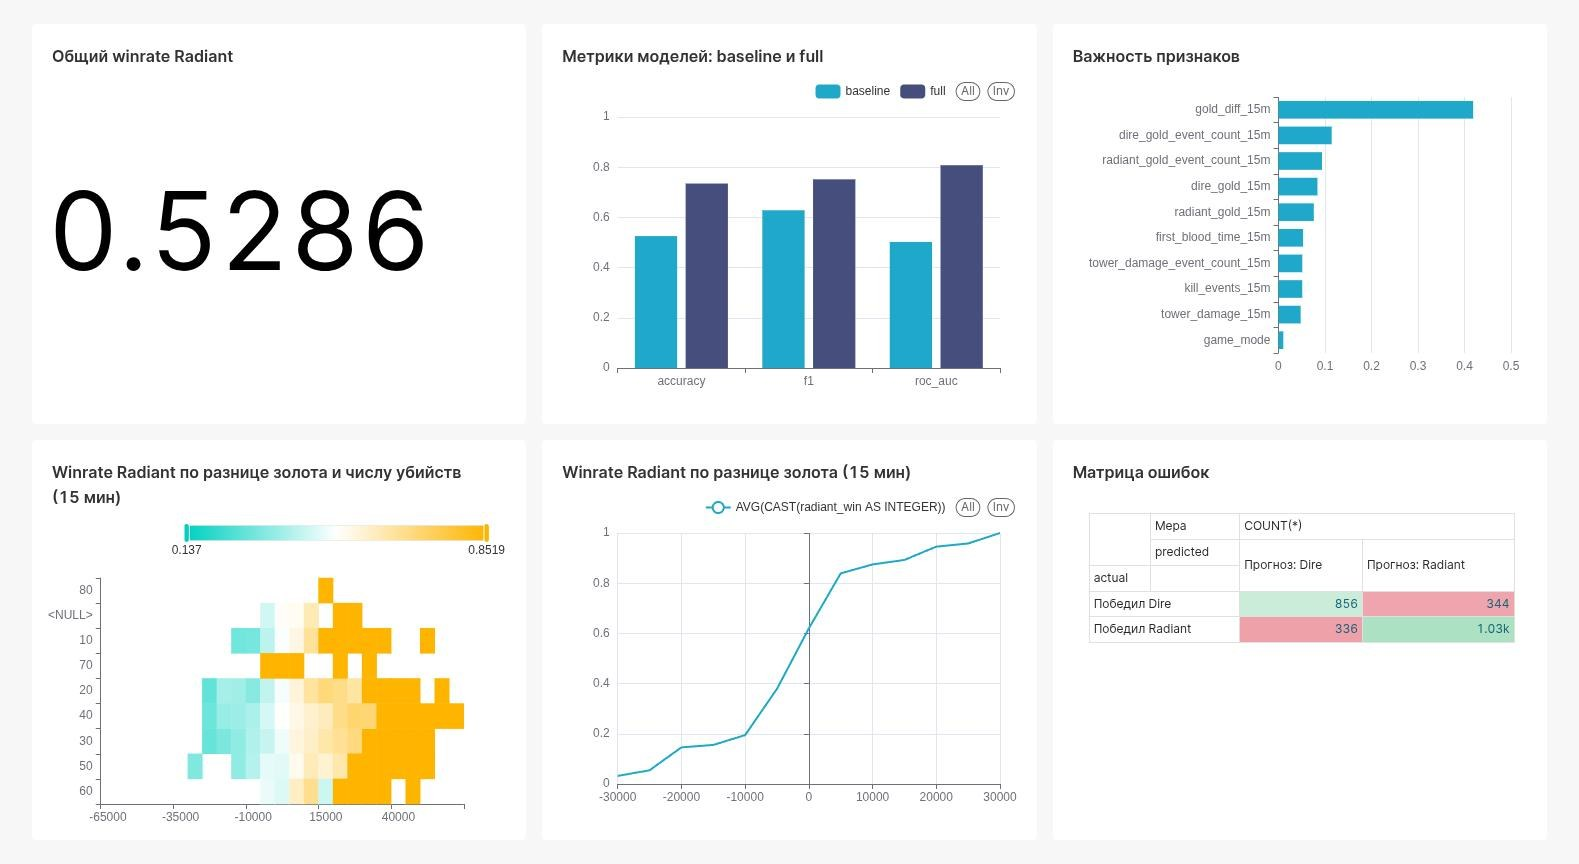


### 10.10. Сохранение экспериментальных артефактов

Модель и метрики сохраняются локально в среде Colab. Это не публикация модели в реестр LHlakehouse и не замена Spark ML-процесса платформы.

In [ ]:
if winner_mart_ready:
    model_path = ARTIFACT_DIR / "case16_winner_model.joblib"
    metrics_path = ARTIFACT_DIR / "case16_metrics.json"
    importance_path = ARTIFACT_DIR / "case16_feature_importance.csv"

    joblib.dump({
        "model": winner_model,
        "features": winner_features_final,
        "target": "radiant_win",
        "target_mapping": {"False": 0, "True": 1},
        "mart_table": WINNER_MART,
    }, model_path)

    with metrics_path.open("w", encoding="utf-8") as file:
        json.dump(winner_metrics, file, ensure_ascii=False, indent=2)

    winner_importance.to_csv(importance_path, index=False)

    print("Модель:", model_path.resolve())
    print("Метрики:", metrics_path.resolve())
    print("Важность признаков:", importance_path.resolve())

### 10.11. Ограничения интерпретации

- Корректность `radiant_win` определяется источником метки и JOIN по `match_id`.
- Все признаки должны быть доступны к 15-й минуте; итоговые и постматчевые поля исключаются.
- Случайное train/test-разбиение даёт предварительную оценку; временная валидация и кросс-валидация позволяют оценить устойчивость результата.
- Эксперимент в Colab служит аналитической проверкой MART; промышленное обучение и scoring относятся к платформенному Spark ML-процессу.

## 11. Кейс №19 Duration — оценка длительности матча

**Аналитический вопрос:** можно ли оценить итоговую длительность матча по событиям первых 15 минут?

Сохранённая MART содержит **7 391 матч**. Целевая переменная — `label_duration` из `lakehouse.mart.practice_case_19_ml_match_duration_features` (переименовывается в `duration` при загрузке), в секундах. В признаки включаются только события из окна **[0, 900)**. Итоговая длительность не попадает в матрицу признаков.

### Гипотезы и результаты

| ID | Проверяемый критерий | Результат по сохранённому анализу | Вывод |
|---|---|---|---|
| **D1** | При `|gold_diff_15m| ≥ 5 000` медианная длительность отличается от группы `|gold_diff_15m| ≤ 1 000` минимум на 3 минуты | `radiant_gold_15m` и `dire_gold_15m` — два наиболее важных признака модели (0,488 и 0,243). Сравнение указанных групп отдельно не выполнено. | **Не проверена.** Feature importance не подтверждает требуемую разницу медиан. |
| **D2** | При ≥10 суммарных убийствах и смертях против ≤5 событий медианная длительность отличается минимум на 3 минуты | `kills_diff_15m` — 0,00033; `radiant_kills_15m` — 0,00088; `dire_kills_15m` — 0,00099. Отдельное сравнение групп не выполнено. | **Не подтверждена текущими результатами; пороговый тест не проведён.** Низкая важность не является доказательством отсутствия связи. |
| **D3** | При ≥2 потерянных башнях медианная длительность минимум на 3 минуты меньше, чем при 0 потерянных башнях | `tower_deaths_total_15m` присутствует в MART; важность — 0,0329. Направление и размер разницы медиан не рассчитаны. | **Не проверена.** |
| **D4** | Хотя бы один пропуск ранних признаков повышает MAE минимум на 20% относительно матчей без пропусков | В модели используются индикаторы пропусков, но MAE по группам с пропусками и без них в сохранённом выполнении не сравнивалась. | **Не проверена.** |
| **D5** | Gradient Boosting снижает MAE и RMSE не менее чем на 25% относительно медианного baseline | На holdout из **1 479** матчей: MAE **361,36** против **531,77** сек (−32,1%); RMSE **471,94** против **668,89** сек (−29,4%); R² модели **0,501**, baseline **−0,002**. | **Подтверждена** на случайном holdout относительно глобального медианного baseline. |

D1–D4 описывают отдельные связи и качество покрытия; их нельзя считать доказанными по одной только feature importance. D5 подтверждает экспериментальное превосходство модели над выбранным baseline, но ещё не доказывает готовность прогноза к бизнес-применению.

### Airflow DAG — Case 19 Duration

**DAG: подготовка признаков и витрины Duration**

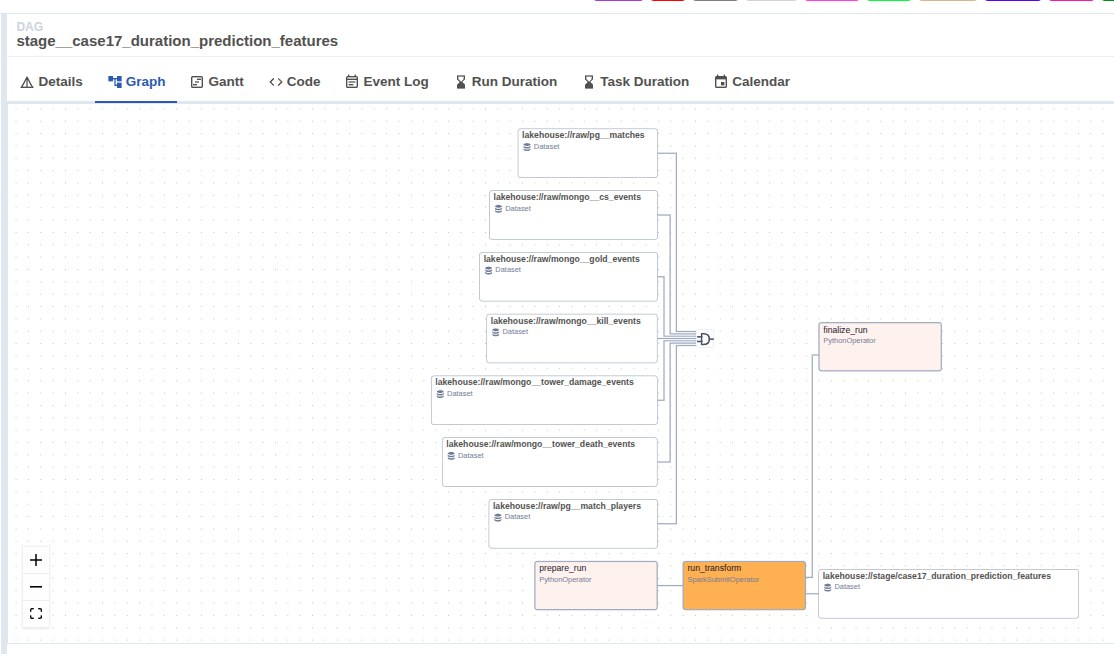


### Data Lineage — Case 19 Duration

**Зависимости источников, STAGE и MART**

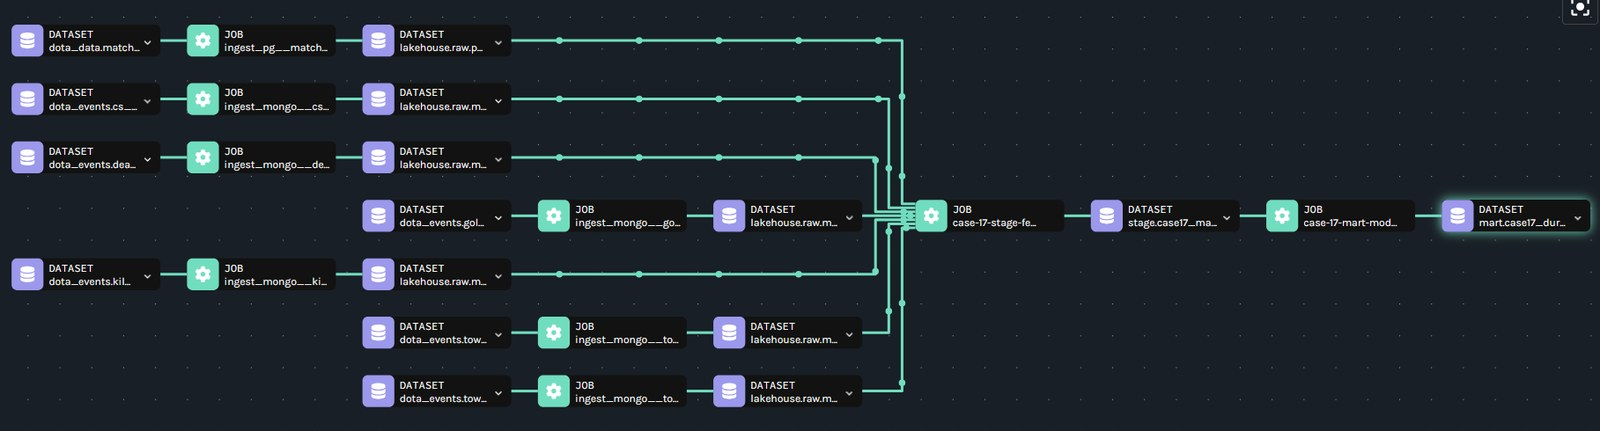


### 11.1. Проверка схемы и качества Duration MART

In [18]:
# Case 19: используем фактическую MART из Lakehouse.
# В ней target называется label_duration, а не duration.
DURATION_MART = "lakehouse.mart.practice_case_19_ml_match_duration_features"
DURATION_TARGET_COLUMN = "label_duration"

DURATION_NUMERIC_CANDIDATES = []
DURATION_FLAGS = []

try:
    duration_schema = query_df(f"DESCRIBE {DURATION_MART}")
    duration_columns = (
        duration_schema["Column"].astype(str).tolist()
        if "Column" in duration_schema.columns
        else duration_schema.iloc[:, 0].astype(str).tolist()
    )
    print("Источник:", DURATION_MART)
    print("Колонки:", duration_columns)

    required_duration = {"match_id", DURATION_TARGET_COLUMN}
    missing_duration = required_duration - set(duration_columns)
    if missing_duration:
        raise ValueError(
            f"В Duration MART отсутствуют обязательные колонки: {sorted(missing_duration)}"
        )

    # Все остальные поля, кроме ID и target, — доступные признаки.
    duration_features = [
        col for col in duration_columns
        if col not in {"match_id", DURATION_TARGET_COLUMN}
    ]
    DURATION_NUMERIC_CANDIDATES = [
        col for col in duration_features
        if col != "rank_is_missing"
    ]
    DURATION_FLAGS = [
        col for col in duration_features
        if col == "rank_is_missing" or col.endswith("_flag")
    ]

    print("Найденные признаки:", duration_features)
    print("Количество признаков:", len(duration_features))

    duration_profile = query_df(f"""
        SELECT
            COUNT(*) AS rows_count,
            COUNT(DISTINCT match_id) AS distinct_matches,
            COUNT_IF(match_id IS NULL) AS null_match_id,
            COUNT_IF({DURATION_TARGET_COLUMN} IS NULL) AS null_target,
            COUNT_IF({DURATION_TARGET_COLUMN} <= 0) AS non_positive_target,
            MIN({DURATION_TARGET_COLUMN}) AS min_target,
            APPROX_PERCENTILE({DURATION_TARGET_COLUMN}, 0.5) AS median_target,
            MAX({DURATION_TARGET_COLUMN}) AS max_target
        FROM {DURATION_MART}
    """)
    display(duration_profile)

    duration_mart_ready = True
except Exception as exc:
    duration_mart_ready = False
    duration_features = []
    print(f"Duration MART недоступна: {type(exc).__name__}: {exc}")

Источник: lakehouse.mart.practice_case_19_ml_match_duration_features
Колонки: ['match_id', 'label_duration', 'game_mode', 'lobby_type', 'first_blood_time', 'avg_rank', 'rank_is_missing', 'radiant_gold_15m', 'dire_gold_15m', 'gold_diff_15m', 'radiant_xp_15m', 'dire_xp_15m', 'xp_diff_15m', 'radiant_cs_15m', 'dire_cs_15m', 'cs_diff_15m', 'radiant_kills_15m', 'dire_kills_15m', 'kills_diff_15m', 'radiant_deaths_15m', 'dire_deaths_15m', 'deaths_diff_15m', 'tower_deaths_total_15m', 'radiant_towers_alive_15m', 'dire_towers_alive_15m', 'towers_alive_diff_15m', 'buildings_destroyed_total_15m', 'radiant_towers_lost_15m', 'dire_towers_lost_15m', 'radiant_barracks_lost_15m', 'dire_barracks_lost_15m', 'radiant_hero_dmg_15m', 'dire_hero_dmg_15m', 'hero_dmg_diff_15m', 'avg_level_15m', 'max_level_15m', 'streaks_total_15m', 'max_streak_15m']
Найденные признаки: ['game_mode', 'lobby_type', 'first_blood_time', 'avg_rank', 'rank_is_missing', 'radiant_gold_15m', 'dire_gold_15m', 'gold_diff_15m', 'radiant_xp

,rows_count,distinct_matches,null_match_id,null_target,non_positive_target,min_target,median_target,max_target
0,7391,7391,0,0,0,905,2135,5335


Проверка столбцов RAW:

In [19]:
duration_sources = [
    "dota_duration_15min_matches",
    "dota_duration_15min_match_players",
    "dota_duration_15min_gold_events",
    "dota_duration_15min_kill_events"
]

for table in duration_sources:
    print(f"\n{'=' * 60}")
    print(table)
    print("=" * 60)

    display(query_df(
        f"DESCRIBE lakehouse.raw.{table}"
    ))


dota_duration_15min_matches


,Column,Type,Extra,Comment
0,match_id,bigint,,
1,game_mode,integer,,
2,duration,integer,,
3,first_blood_time,integer,,
4,src_modified_stamp,timestamp(6) with time zone,,
5,sys_insert_stamp,timestamp(6) with time zone,,



dota_duration_15min_match_players


,Column,Type,Extra,Comment
0,match_id,bigint,,
1,player_slot,integer,,
2,account_id,bigint,,
3,src_modified_stamp,timestamp(6) with time zone,,
4,sys_insert_stamp,timestamp(6) with time zone,,



dota_duration_15min_gold_events


,Column,Type,Extra,Comment
0,id,varchar,,
1,match_id,bigint,,
2,steam_account_id,bigint,,
3,time,integer,,
4,amount,integer,,
5,reason,varchar,,
6,npcid,integer,,
7,src_modified_stamp,timestamp(6) with time zone,,
8,sys_insert_stamp,timestamp(6) with time zone,,



dota_duration_15min_kill_events


,Column,Type,Extra,Comment
0,id,varchar,,
1,match_id,bigint,,
2,steam_account_id,bigint,,
3,attacker,bigint,,
4,target,bigint,,
5,time,integer,,
6,src_modified_stamp,timestamp(6) with time zone,,
7,sys_insert_stamp,timestamp(6) with time zone,,


In [20]:
query = """
SHOW TABLES FROM lakehouse.raw LIKE '%practice_case_19_ml%'
"""

cursor.execute(query)

for row in cursor.fetchall():
    print(row[0])

practice_case_19_ml_building_events
practice_case_19_ml_cs_events
practice_case_19_ml_death_events
practice_case_19_ml_experience_events
practice_case_19_ml_gold_events
practice_case_19_ml_hero_damage_events
practice_case_19_ml_ingest_batches
practice_case_19_ml_kill_events
practice_case_19_ml_match_players
practice_case_19_ml_matches
practice_case_19_ml_player_update_level_events
practice_case_19_ml_purchase_events
practice_case_19_ml_rune_events
practice_case_19_ml_streak_events
practice_case_19_ml_tower_damage_events
practice_case_19_ml_tower_death_events
practice_case_19_ml_ward_events


In [21]:
tables = [
    "practice_case_19_ml_matches",
    "practice_case_19_ml_match_players",
    "practice_case_19_ml_gold_events",
    "practice_case_19_ml_kill_events",
    "practice_case_19_ml_ingest_batches"
]

for table in tables:
    print(f"\n{'=' * 70}")
    print(f"TABLE: {table}")
    print("=" * 70)

    cursor.execute(f"""
        DESCRIBE lakehouse.raw.{table}
    """)

    for row in cursor.fetchall():
        print(f"{row[0]:35} {row[1]}")


TABLE: practice_case_19_ml_matches
match_id                            bigint
duration                            integer
first_blood_time                    integer
game_mode                           integer
lobby_type                          integer
src_modified_stamp                  timestamp(6) with time zone
sys_insert_stamp                    timestamp(6) with time zone

TABLE: practice_case_19_ml_match_players
match_id                            bigint
player_slot                         integer
account_id                          bigint
rank                                integer
src_modified_stamp                  timestamp(6) with time zone
sys_insert_stamp                    timestamp(6) with time zone

TABLE: practice_case_19_ml_gold_events
id                                  varchar
match_id                            bigint
steam_account_id                    bigint
time                                integer
amount                              integer
src_modified_st

In [22]:
query = """
SELECT
    collection,
    batch_id,
    match_count,
    doc_count,
    status,
    attempt,
    started_at,
    finished_at,
    error
FROM lakehouse.raw.practice_case_19_ml_ingest_batches
ORDER BY started_at DESC
"""

cursor.execute(query)

columns = [column[0] for column in cursor.description]

for row in cursor.fetchall():
    print(dict(zip(columns, row)))

{'collection': 'ward_events', 'batch_id': 99, 'match_count': 100, 'doc_count': 2752, 'status': 'success', 'attempt': 1, 'started_at': datetime.datetime(2026, 11, 13, 12, 12, 49, tzinfo=zoneinfo.ZoneInfo(key='UTC')), 'finished_at': datetime.datetime(2026, 11, 13, 12, 12, 49, tzinfo=zoneinfo.ZoneInfo(key='UTC')), 'error': ''}
{'collection': 'ward_events', 'batch_id': 98, 'match_count': 100, 'doc_count': 2718, 'status': 'success', 'attempt': 1, 'started_at': datetime.datetime(2026, 11, 13, 12, 12, 45, tzinfo=zoneinfo.ZoneInfo(key='UTC')), 'finished_at': datetime.datetime(2026, 11, 13, 12, 12, 46, tzinfo=zoneinfo.ZoneInfo(key='UTC')), 'error': ''}
{'collection': 'ward_events', 'batch_id': 97, 'match_count': 100, 'doc_count': 2051, 'status': 'success', 'attempt': 1, 'started_at': datetime.datetime(2026, 11, 13, 12, 12, 40, tzinfo=zoneinfo.ZoneInfo(key='UTC')), 'finished_at': datetime.datetime(2026, 11, 13, 12, 12, 41, tzinfo=zoneinfo.ZoneInfo(key='UTC')), 'error': ''}
{'collection': 'ward_e

In [23]:
for table in [
    "practice_case_19_ml_gold_events",
    "practice_case_19_ml_kill_events"
]:
    print(f"\n{table}")

    cursor.execute(f"""
        SELECT
            batch_id,
            COUNT(*) AS row_count,
            COUNT(DISTINCT id) AS unique_events,
            COUNT(DISTINCT match_id) AS unique_matches
        FROM lakehouse.raw.{table}
        GROUP BY batch_id
        ORDER BY batch_id DESC
    """)

    for row in cursor.fetchall():
        print(row)


practice_case_19_ml_gold_events
[99, 55078, 55078, 73]
[98, 58297, 58297, 80]
[97, 56733, 56733, 78]
[96, 63452, 63452, 84]
[95, 54154, 54154, 74]
[94, 50788, 50788, 69]
[93, 54034, 54034, 73]
[92, 60127, 60127, 82]
[91, 69822, 69822, 93]
[90, 41805, 41805, 55]
[89, 64207, 64207, 87]
[88, 44399, 44399, 62]
[87, 44783, 44783, 61]
[86, 46138, 46138, 64]
[85, 46285, 46285, 62]
[84, 61336, 61336, 83]
[83, 56269, 56269, 76]
[82, 57839, 57839, 77]
[81, 60504, 60504, 80]
[80, 49573, 49573, 69]
[79, 49035, 49035, 65]
[78, 42824, 42824, 60]
[77, 64621, 64621, 89]
[76, 63957, 63957, 88]
[75, 54869, 54869, 72]
[74, 59337, 59337, 80]
[73, 50966, 50966, 69]
[72, 51126, 51126, 69]
[71, 65114, 65114, 88]
[70, 54140, 54140, 74]
[69, 50755, 50755, 68]
[68, 49361, 49361, 67]
[67, 58163, 58163, 83]
[66, 59545, 59545, 79]
[65, 47564, 47564, 64]
[64, 59235, 59235, 82]
[63, 52636, 52636, 72]
[62, 46945, 46945, 63]
[61, 47950, 47950, 64]
[60, 59018, 59018, 80]
[59, 59135, 59135, 80]
[58, 56646, 56646, 79]
[

### 11.2. Загрузка MART и анализ покрытия

Используем фактическую витрину `lakehouse.mart.practice_case_19_ml_match_duration_features`. В ней целевая переменная называется `label_duration`; при загрузке она переименовывается в `duration`, чтобы остальные ячейки обучения и визуализации могли использовать единый интерфейс. Все остальные колонки, кроме `match_id`, используются как кандидаты в признаки.

In [25]:
BATCH_SIZE = 10_000
if duration_mart_ready:
    # label_duration приводим к общему имени duration, которое используется
    # дальше в train/test, метриках и визуализациях.
    duration_select_cols = ["match_id", "duration"] + duration_features
    duration_feature_sql = ", ".join(f'"{col}"' for col in duration_features)
    duration_select_sql = (
        f'"match_id", "{DURATION_TARGET_COLUMN}" AS "duration"'
        + (f", {duration_feature_sql}" if duration_feature_sql else "")
    )

    duration_cursor = conn.cursor()
    duration_chunks = []
    try:
        duration_cursor.execute(f"SELECT {duration_select_sql} FROM {DURATION_MART}")
        while True:
            chunk = duration_cursor.fetchmany(BATCH_SIZE)
            if not chunk:
                break
            duration_chunks.append(pd.DataFrame(chunk, columns=duration_select_cols))
    finally:
        duration_cursor.close()

    duration_df = (
        pd.concat(duration_chunks, ignore_index=True)
        if duration_chunks
        else pd.DataFrame(columns=duration_select_cols)
    )
    print("Загружено матчей:", len(duration_df))
    display(duration_df.head())

    if duration_df.empty:
        raise ValueError("Duration MART существует, но не содержит строк.")

    duplicate_duration_ids = int(duration_df["match_id"].duplicated().sum())
    print("Дубликаты match_id:", duplicate_duration_ids)
    if duplicate_duration_ids:
        raise ValueError("Duration MART должна содержать одну строку на match_id.")

    duration_df["duration"] = pd.to_numeric(duration_df["duration"], errors="coerce")
    invalid_duration_count = int(
        (duration_df["duration"].isna() | (duration_df["duration"] <= 0)).sum()
    )
    print("NULL или неположительная duration:", invalid_duration_count)
    duration_df = duration_df.loc[
        duration_df["duration"].notna() & (duration_df["duration"] > 0)
    ].reset_index(drop=True)

    # Boolean/int/double признаки приводим к числовому виду для sklearn.
    for col in duration_features:
        duration_df[col] = pd.to_numeric(duration_df[col], errors="coerce")

    coverage_columns = [c for c in DURATION_FLAGS if c in duration_df.columns]
    if coverage_columns:
        display(
            duration_df[coverage_columns]
            .apply(pd.to_numeric, errors="coerce")
            .mean()
            .rename("share_flagged")
            .to_frame()
        )

    numeric_present = [c for c in duration_features if c in duration_df.columns]
    if numeric_present:
        duration_missing_report = pd.DataFrame({
            "null_share": duration_df[numeric_present].isna().mean(),
            "non_null_count": duration_df[numeric_present].notna().sum(),
        }).sort_values("null_share", ascending=False)
        display(duration_missing_report)

    print(
        "Target label_duration загружен как duration. "
        "Min/median/max должны соответствовать секундам, "
        "поскольку последующие графики и метрики подписаны в секундах/минутах."
    )

Загружено матчей: 7391


,match_id,duration,game_mode,lobby_type,first_blood_time,avg_rank,rank_is_missing,radiant_gold_15m,dire_gold_15m,gold_diff_15m,...,dire_towers_lost_15m,radiant_barracks_lost_15m,dire_barracks_lost_15m,radiant_hero_dmg_15m,dire_hero_dmg_15m,hero_dmg_diff_15m,avg_level_15m,max_level_15m,streaks_total_15m,max_streak_15m
0,9045580987,1203,23,0,11,48.428571,True,52424,35312,17112,...,0,0,0,NaN,NaN,0,NaN,NaN,NaN,NaN
1,9045587598,2609,22,7,109,71.900000,False,18008,14716,3292,...,0,0,0,NaN,NaN,0,NaN,NaN,NaN,NaN
2,9045602092,2872,22,7,47,40.200000,False,11747,15827,-4080,...,0,0,0,19857.0,33847.0,-13990,8.1,10.0,3.0,4.0
3,9045628708,1658,22,0,84,46.000000,True,25659,8093,17566,...,0,0,0,32197.0,16178.0,16019,8.3,17.0,51.0,32.0
4,9045653907,1372,22,7,0,52.000000,False,21490,10037,11453,...,0,0,0,36631.0,26401.0,10230,8.7,11.0,10.0,7.0


Дубликаты match_id: 0
NULL или неположительная duration: 0


,share_flagged
rank_is_missing,0.413341


,null_share,non_null_count
max_streak_15m,0.366933,4679
streaks_total_15m,0.366933,4679
max_level_15m,0.267758,5412
avg_level_15m,0.267758,5412
dire_hero_dmg_15m,0.258558,5480
radiant_hero_dmg_15m,0.258558,5480
radiant_towers_alive_15m,0.056826,6971
tower_deaths_total_15m,0.056826,6971
dire_towers_alive_15m,0.056826,6971
avg_rank,0.017860,7259


Target label_duration загружен как duration. Проверь min/median/max выше: значения должны быть в секундах, поскольку последующие графики и метрики подписаны в секундах/минутах.


### 11.3. Подготовка признаков и train/test split

`match_id` используется только для контроля и не попадает в признаки. `duration` — target и не включается в feature matrix. Импутация обучается только на train-части через Pipeline.

In [26]:
import pyspark
print(pyspark.__version__)

4.0.5


In [27]:
if duration_mart_ready:
    from sklearn.base import clone
    from sklearn.ensemble import GradientBoostingRegressor
    from sklearn.dummy import DummyRegressor
    from sklearn.impute import SimpleImputer
    from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
    from sklearn.model_selection import train_test_split
    from sklearn.pipeline import Pipeline

    duration_model_features = [
        c for c in DURATION_NUMERIC_CANDIDATES + DURATION_FLAGS
        if c in duration_df.columns
    ]
    X_duration = duration_df[duration_model_features].apply(pd.to_numeric, errors="coerce")
    y_duration = duration_df["duration"].astype(float)
    duration_ids = duration_df["match_id"]

    all_null_duration_features = [
        c for c in X_duration.columns if X_duration[c].notna().sum() == 0
    ]
    if all_null_duration_features:
        print("Исключены полностью пустые признаки:", all_null_duration_features)
        X_duration = X_duration.drop(columns=all_null_duration_features)

    if X_duration.shape[1] == 0:
        raise ValueError("В Duration MART нет доступных непустых признаков.")

    X_train_d, X_test_d, y_train_d, y_test_d, ids_train_d, ids_test_d = train_test_split(
        X_duration,
        y_duration,
        duration_ids,
        test_size=0.20,
        random_state=42,
    )
    if set(ids_train_d).intersection(set(ids_test_d)):
        raise ValueError("Обнаружено пересечение match_id между train и test.")

    print("Train:", len(X_train_d), "Test:", len(X_test_d))
    print("Features:", list(X_duration.columns))

Train: 5912 Test: 1479
Features: ['game_mode', 'lobby_type', 'first_blood_time', 'avg_rank', 'radiant_gold_15m', 'dire_gold_15m', 'gold_diff_15m', 'radiant_xp_15m', 'dire_xp_15m', 'xp_diff_15m', 'radiant_cs_15m', 'dire_cs_15m', 'cs_diff_15m', 'radiant_kills_15m', 'dire_kills_15m', 'kills_diff_15m', 'radiant_deaths_15m', 'dire_deaths_15m', 'deaths_diff_15m', 'tower_deaths_total_15m', 'radiant_towers_alive_15m', 'dire_towers_alive_15m', 'towers_alive_diff_15m', 'buildings_destroyed_total_15m', 'radiant_towers_lost_15m', 'dire_towers_lost_15m', 'radiant_barracks_lost_15m', 'dire_barracks_lost_15m', 'radiant_hero_dmg_15m', 'dire_hero_dmg_15m', 'hero_dmg_diff_15m', 'avg_level_15m', 'max_level_15m', 'streaks_total_15m', 'max_streak_15m', 'rank_is_missing']


### 11.4. Проверка гипотез D1-D3

In [ ]:
# D1-D3: сравнение медианной длительности между группами по числовым критериям гипотез.
# Код использует только признаки первых 15 минут и target duration в секундах.
from scipy.stats import mannwhitneyu

hypothesis_comparisons = []

def add_duration_group_comparison(hypothesis, group_a_name, group_a_mask, group_b_name, group_b_mask, expected_direction):
    valid = duration_df["duration"].notna()
    mask_a = valid & group_a_mask.fillna(False)
    mask_b = valid & group_b_mask.fillna(False)
    values_a = duration_df.loc[mask_a, "duration"]
    values_b = duration_df.loc[mask_b, "duration"]
    if len(values_a) < 2 or len(values_b) < 2:
        hypothesis_comparisons.append({
            "hypothesis": hypothesis, "group_a": group_a_name, "n_a": len(values_a),
            "group_b": group_b_name, "n_b": len(values_b), "status": "insufficient data"
        })
        return
    test = mannwhitneyu(values_a, values_b, alternative="two-sided")
    diff_seconds = float(values_a.median() - values_b.median())
    hypothesis_comparisons.append({
        "hypothesis": hypothesis,
        "group_a": group_a_name,
        "n_a": len(values_a),
        "median_a_min": float(values_a.median() / 60),
        "group_b": group_b_name,
        "n_b": len(values_b),
        "median_b_min": float(values_b.median() / 60),
        "median_difference_a_minus_b_sec": diff_seconds,
        "mann_whitney_p": float(test.pvalue),
        "expected_direction": expected_direction,
        "status": "tested"
    })

if "gold_diff_15m" in duration_df.columns:
    gold_abs = pd.to_numeric(duration_df["gold_diff_15m"], errors="coerce").abs()
    add_duration_group_comparison(
        "D1", "|gold_diff_15m| >= 5000", gold_abs >= 5000,
        "|gold_diff_15m| <= 1000", gold_abs <= 1000,
        "absolute median difference >= 180 sec"
    )

kill_death_cols = [c for c in [
    "radiant_kills_15m", "dire_kills_15m", "radiant_deaths_15m", "dire_deaths_15m"
] if c in duration_df.columns]
if len(kill_death_cols) == 4:
    total_kill_death_events = duration_df[kill_death_cols].apply(pd.to_numeric, errors="coerce").sum(axis=1, min_count=4)
    add_duration_group_comparison(
        "D2", "kills+deaths >= 10", total_kill_death_events >= 10,
        "kills+deaths <= 5", total_kill_death_events <= 5,
        "absolute median difference >= 180 sec"
    )

if "tower_deaths_total_15m" in duration_df.columns:
    tower_losses = pd.to_numeric(duration_df["tower_deaths_total_15m"], errors="coerce")
    add_duration_group_comparison(
        "D3", "tower deaths >= 2", tower_losses >= 2,
        "tower deaths = 0", tower_losses == 0,
        "group >=2 has median at least 180 sec shorter"
    )

duration_d1_d3_results = pd.DataFrame(hypothesis_comparisons)
display(duration_d1_d3_results)

### 11.5. Median baseline и Gradient Boosting Regressor

Сравниваем простейший baseline (предсказание медианы train) с Gradient Boosting. Метрики MAE/RMSE измеряются в секундах, R² показывает долю объяснённой дисперсии.

In [28]:
if duration_mart_ready:
    duration_models = {
        "Median baseline": Pipeline([
            ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
            ("model", DummyRegressor(strategy="median")),
        ]),
        "Gradient Boosting": Pipeline([
            ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
            ("model", GradientBoostingRegressor(
                n_estimators=200,
                learning_rate=0.05,
                max_depth=2,
                random_state=42,
            )),
        ]),
    }

    duration_metric_rows = []
    duration_predictions = {}

    for model_name, model in duration_models.items():
        model.fit(X_train_d, y_train_d)
        prediction = model.predict(X_test_d)
        duration_predictions[model_name] = prediction
        duration_metric_rows.append({
            "model": model_name,
            "MAE_seconds": mean_absolute_error(y_test_d, prediction),
            "RMSE_seconds": mean_squared_error(y_test_d, prediction) ** 0.5,
            "R2": r2_score(y_test_d, prediction),
            "train_rows": len(X_train_d),
            "test_rows": len(X_test_d),
        })

    duration_metrics_df = pd.DataFrame(duration_metric_rows)
    display(duration_metrics_df)

,model,MAE_seconds,RMSE_seconds,R2,train_rows,test_rows
0,Median baseline,531.769777,668.886263,-0.001595,5912,1479
1,Gradient Boosting,361.360808,471.939944,0.501390,5912,1479


### D5 — результат сравнения моделей

Сохранённый результат: Median baseline — MAE **531,77 сек**, RMSE **668,89 сек**, R² **−0,002**; Gradient Boosting — MAE **361,36 сек**, RMSE **471,94 сек**, R² **0,501**. Сокращение MAE составляет около **32,1%**, RMSE — около **29,4%** на тестовой выборке из 1 479 матчей. Критерий D5 (не менее 25% по обеим ошибкам) выполнен.

### 11.6. Анализ ошибок и важность признаков

,actual_duration,predicted_duration,residual,absolute_error
count,1479.000000,1479.000000,1479.000000,1479.000000
mean,2167.189317,2172.338792,-5.149475,361.360808
std,668.579646,471.214915,472.071468,303.657739
min,907.000000,1014.355161,-1477.269529,0.118317
25%,1700.000000,1674.684511,-323.812053,135.637407
50%,2125.000000,2371.430013,-73.355161,296.520493
75%,2577.500000,2552.312195,260.485727,521.437687
max,5135.000000,2963.781889,2565.390982,2565.390982


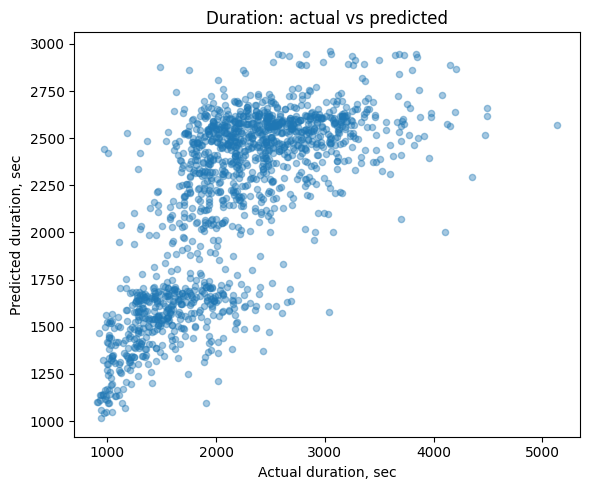

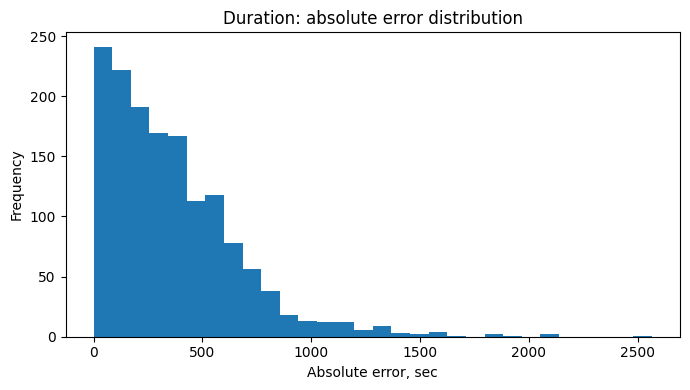

,feature,importance
4,radiant_gold_15m,0.488139
5,dire_gold_15m,0.242725
7,radiant_xp_15m,0.055046
6,gold_diff_15m,0.051732
9,xp_diff_15m,0.044124
19,tower_deaths_total_15m,0.032875
22,towers_alive_diff_15m,0.011002
8,dire_xp_15m,0.010635
3,avg_rank,0.009144
2,first_blood_time,0.006331


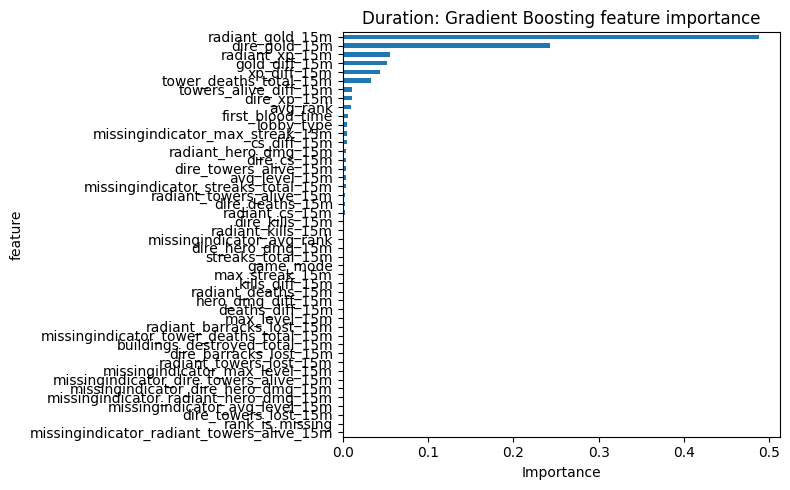

In [32]:
import matplotlib.pyplot as plt
if duration_mart_ready:
    duration_gbt = duration_models["Gradient Boosting"]
    duration_gbt_pred = duration_predictions["Gradient Boosting"]

    duration_error_df = pd.DataFrame({
        "match_id": ids_test_d.to_numpy(),
        "actual_duration": y_test_d.to_numpy(),
        "predicted_duration": duration_gbt_pred,
    })
    duration_error_df["residual"] = (
        duration_error_df["actual_duration"] - duration_error_df["predicted_duration"]
    )
    duration_error_df["absolute_error"] = duration_error_df["residual"].abs()

    display(duration_error_df[["actual_duration", "predicted_duration", "residual", "absolute_error"]].describe())

    ax = duration_error_df.plot(
        kind="scatter", x="actual_duration", y="predicted_duration",
        title="Duration: actual vs predicted", figsize=(6, 5), alpha=0.4
    )
    ax.set_xlabel("Actual duration, sec")
    ax.set_ylabel("Predicted duration, sec")
    plt.tight_layout()
    plt.show()

    ax = duration_error_df["absolute_error"].plot(
        kind="hist", bins=30, title="Duration: absolute error distribution", figsize=(7, 4)
    )
    ax.set_xlabel("Absolute error, sec")
    plt.tight_layout()
    plt.show()

    duration_imputer = duration_gbt.named_steps["imputer"]
    duration_estimator = duration_gbt.named_steps["model"]
    duration_transformed_features = duration_imputer.get_feature_names_out(list(X_duration.columns))
    duration_importance = pd.DataFrame({
        "feature": duration_transformed_features,
        "importance": duration_estimator.feature_importances_,
    }).sort_values("importance", ascending=False)
    display(duration_importance)

    ax = duration_importance.sort_values("importance").plot(
        kind="barh", x="feature", y="importance", legend=False,
        title="Duration: Gradient Boosting feature importance", figsize=(8, 5)
    )
    ax.set_xlabel("Importance")
    plt.tight_layout()
    plt.show()

### 11.6.1. Проверка D4 — ошибка при пропусках

In [ ]:
# D4: сравнение MAE на holdout для матчей с пропусками хотя бы одного раннего признака
# и матчей без пропусков. Пропуски определяются до импутации.
duration_holdout_missing = X_test_d.isna().any(axis=1).to_numpy()
duration_holdout_errors = pd.DataFrame({
    "match_id": ids_test_d.to_numpy(),
    "has_missing_early_feature": duration_holdout_missing,
    "absolute_error_sec": (y_test_d.to_numpy() - duration_gbt_pred) ** 2,
})
duration_holdout_errors["absolute_error_sec"] = duration_holdout_errors["absolute_error_sec"] ** 0.5

d4_mae = duration_holdout_errors.groupby("has_missing_early_feature")["absolute_error_sec"].agg(
    matches="count", mae_sec="mean"
).reset_index()
display(d4_mae)

if set(d4_mae["has_missing_early_feature"]) == {False, True}:
    clean_mae = float(d4_mae.loc[~d4_mae["has_missing_early_feature"], "mae_sec"].iloc[0])
    missing_mae = float(d4_mae.loc[d4_mae["has_missing_early_feature"], "mae_sec"].iloc[0])
    increase_pct = (missing_mae / clean_mae - 1) * 100 if clean_mae else float("nan")
    print(f"MAE increase for matches with missing features: {increase_pct:.2f}%")
    print("D4 threshold met:", increase_pct >= 20)
else:
    print("D4 comparison requires both holdout groups: with and without missing early features.")

### 11.7. Сводный Dashboard Duration — визуализация в стиле Superset

Шесть панелей для быстрого бизнес-обзора регрессионной модели:
1. ключевые показатели качества;
2. сравнение Median baseline и Gradient Boosting;
3. важность признаков;
4. фактическая и предсказанная длительность;
5. распределение абсолютной ошибки;
6. матрица попаданий по диапазонам длительности.

В отличие от классификационной матрицы Winner, для Duration используем матрицу диапазонов: строки — фактический диапазон, столбцы — предсказанный. Это показывает, насколько часто модель ошибается на соседний или дальний диапазон.

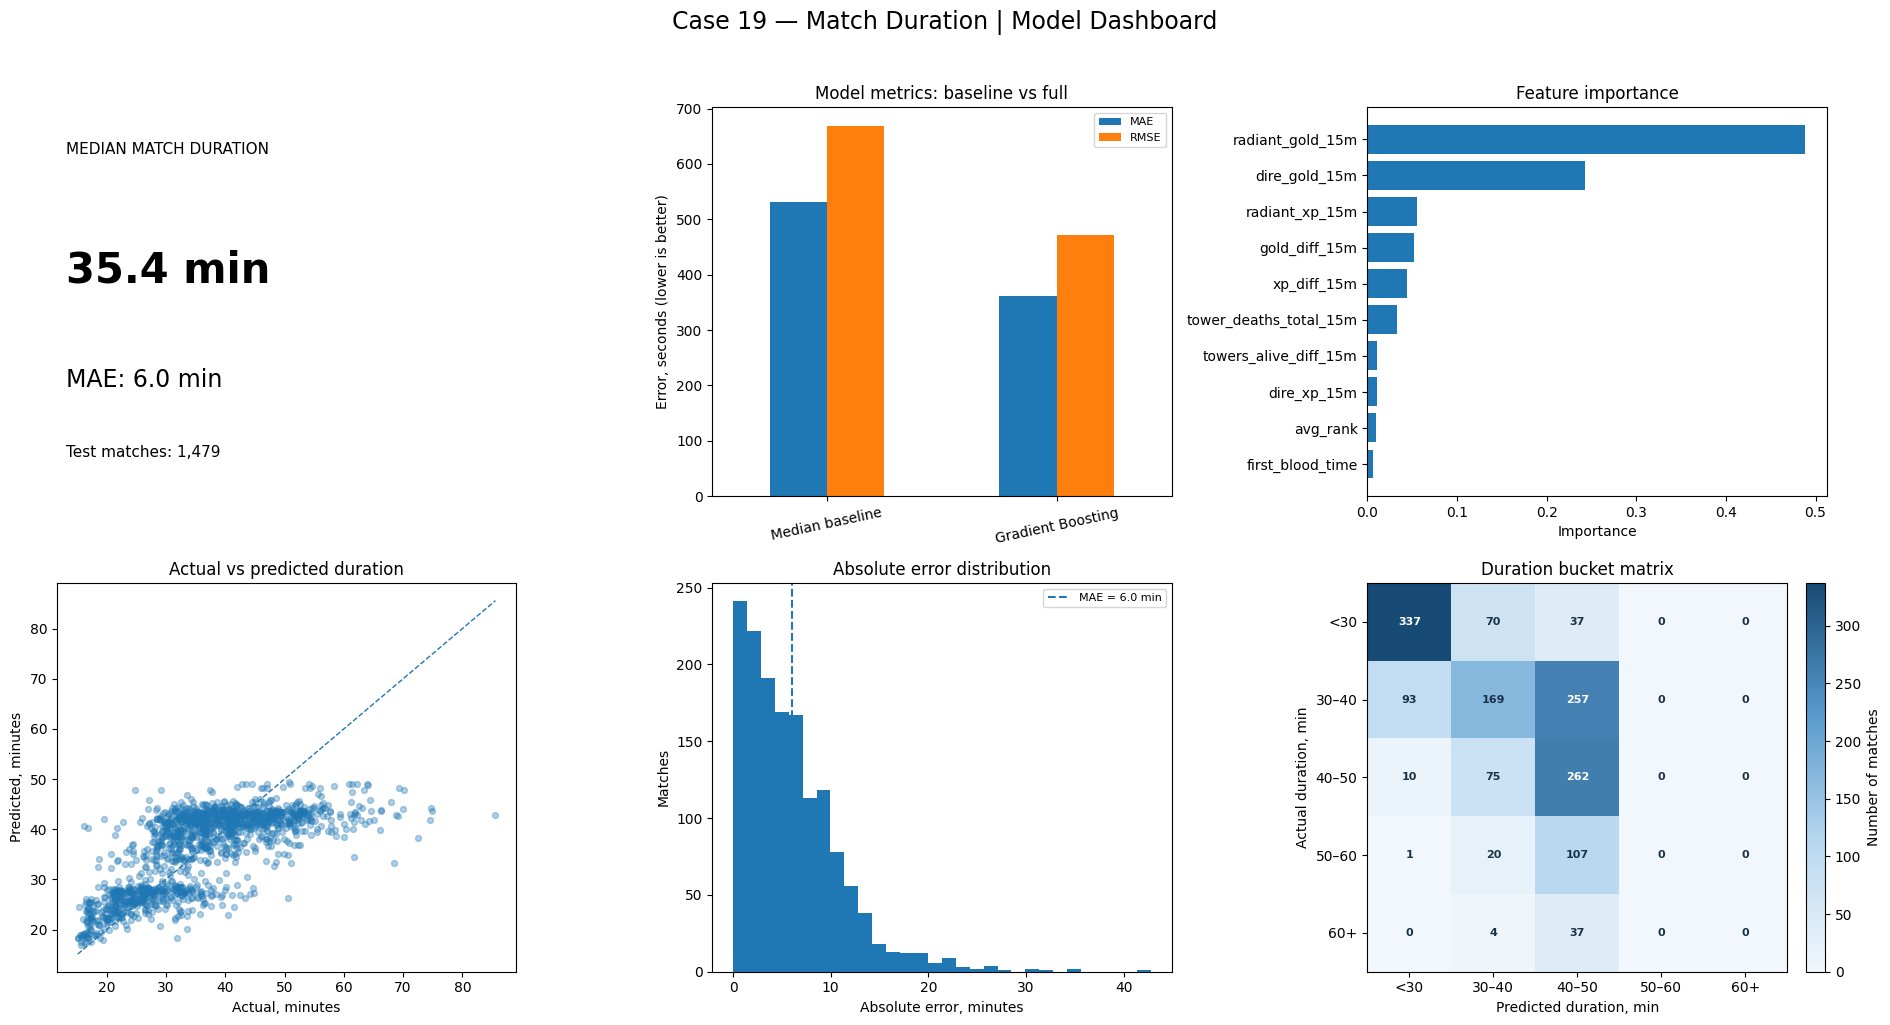

Duration model summary: MAE=361.4 sec (6.02 min), RMSE=471.9 sec, R²=0.501


In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

if duration_mart_ready:
    # Подготавливаем сводные значения для dashboard.
    duration_mae = mean_absolute_error(y_test_d, duration_gbt_pred)
    duration_rmse = mean_squared_error(y_test_d, duration_gbt_pred) ** 0.5
    duration_r2 = r2_score(y_test_d, duration_gbt_pred)
    duration_median_actual_min = float(np.median(y_test_d) / 60)
    duration_mae_min = float(duration_mae / 60)

    fig, axes = plt.subplots(2, 3, figsize=(19, 10))
    fig.suptitle(
        "Case 19 — Match Duration | Model Dashboard",
        fontsize=17,
        y=1.02
    )

    # 1. KPI card.
    ax = axes[0, 0]
    ax.axis("off")
    ax.text(
        0.02, 0.88, "MEDIAN MATCH DURATION",
        fontsize=11, transform=ax.transAxes
    )
    ax.text(
        0.02, 0.55, f"{duration_median_actual_min:.1f} min",
        fontsize=30, fontweight="bold", transform=ax.transAxes
    )
    ax.text(
        0.02, 0.28, f"MAE: {duration_mae_min:.1f} min",
        fontsize=17, transform=ax.transAxes
    )
    ax.text(
        0.02, 0.10, f"Test matches: {len(y_test_d):,}",
        fontsize=11, transform=ax.transAxes
    )

    # 2. Baseline vs full model metrics.
    ax = axes[0, 1]
    metrics_plot = duration_metrics_df.set_index("model")[
        ["MAE_seconds", "RMSE_seconds"]
    ]
    metrics_plot.plot(kind="bar", ax=ax)
    ax.set_title("Model metrics: baseline vs full")
    ax.set_ylabel("Error, seconds (lower is better)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=12)
    ax.legend(["MAE", "RMSE"], fontsize=8)

    # 3. Feature importance.
    ax = axes[0, 2]
    importance_plot = duration_importance.sort_values(
        "importance", ascending=True
    ).tail(10)
    ax.barh(
        importance_plot["feature"],
        importance_plot["importance"]
    )
    ax.set_title("Feature importance")
    ax.set_xlabel("Importance")

    # 4. Actual vs predicted with ideal diagonal.
    ax = axes[1, 0]
    actual_min = y_test_d.min() / 60
    actual_max = y_test_d.max() / 60
    pred_min = np.min(duration_gbt_pred) / 60
    pred_max = np.max(duration_gbt_pred) / 60

    low = min(actual_min, pred_min)
    high = max(actual_max, pred_max)

    ax.scatter(
        y_test_d / 60,
        duration_gbt_pred / 60,
        alpha=0.35,
        s=18
    )
    ax.plot(
        [low, high],
        [low, high],
        linestyle="--",
        linewidth=1
    )
    ax.set_title("Actual vs predicted duration")
    ax.set_xlabel("Actual, minutes")
    ax.set_ylabel("Predicted, minutes")

    # 5. Absolute error distribution.
    ax = axes[1, 1]
    ax.hist(
        duration_error_df["absolute_error"] / 60,
        bins=30
    )
    ax.axvline(
        duration_mae_min,
        linestyle="--",
        linewidth=1.5,
        label=f"MAE = {duration_mae_min:.1f} min"
    )
    ax.set_title("Absolute error distribution")
    ax.set_xlabel("Absolute error, minutes")
    ax.set_ylabel("Matches")
    ax.legend(fontsize=8)

    # 6. Confusion-style matrix for duration buckets.
    ax = axes[1, 2]

    duration_bins = [
        -np.inf,
        30 * 60,
        40 * 60,
        50 * 60,
        60 * 60,
        np.inf
    ]

    duration_labels = ["<30", "30–40", "40–50", "50–60", "60+"]

    actual_bucket = pd.cut(
        y_test_d,
        bins=duration_bins,
        labels=duration_labels
    )

    predicted_bucket = pd.cut(
        pd.Series(duration_gbt_pred, index=y_test_d.index),
        bins=duration_bins,
        labels=duration_labels
    )

    bucket_matrix = pd.crosstab(
        actual_bucket,
        predicted_bucket,
        rownames=["Actual, min"],
        colnames=["Predicted, min"],
        dropna=False
    ).reindex(
        index=duration_labels,
        columns=duration_labels,
        fill_value=0
    )

    # Сине-голубая цветовая палитра.
    cmap = LinearSegmentedColormap.from_list(
        "duration_blues",
        ["#F1F7FC", "#B8D8F0", "#5799CC", "#174A75"]
    )

    image = ax.imshow(
        bucket_matrix.values,
        aspect="auto",
        cmap=cmap
    )

    ax.set_title("Duration bucket matrix")
    ax.set_xlabel("Predicted duration, min")
    ax.set_ylabel("Actual duration, min")

    ax.set_xticks(
        range(len(duration_labels)),
        duration_labels
    )
    ax.set_yticks(
        range(len(duration_labels)),
        duration_labels
    )

    # Подписи значений внутри матрицы.
    threshold = bucket_matrix.values.max() * 0.55

    for row in range(bucket_matrix.shape[0]):
        for col in range(bucket_matrix.shape[1]):
            value = int(bucket_matrix.iloc[row, col])

            ax.text(
                col,
                row,
                f"{value:,}".replace(",", " "),
                ha="center",
                va="center",
                fontsize=8,
                color="white" if value > threshold else "#183247",
                fontweight="bold"
            )

    fig.colorbar(
        image,
        ax=ax,
        fraction=0.046,
        pad=0.04,
        label="Number of matches"
    )

    # Финальное оформление.
    fig.tight_layout()
    plt.show()

    print(
        f"Duration model summary: MAE={duration_mae:.1f} sec "
        f"({duration_mae_min:.2f} min), "
        f"RMSE={duration_rmse:.1f} sec, "
        f"R²={duration_r2:.3f}"
    )

### 11.8. Superset Dashboard Duration

На панели показаны KPI длительности и качества прогноза, сравнение baseline и Gradient Boosting, важность признаков, фактические значения против предсказанных, распределение абсолютной ошибки и матрица попаданий по диапазонам длительности.

### Superset Dashboard — Case 19 Duration

**Сводная панель регрессии длительности матча**

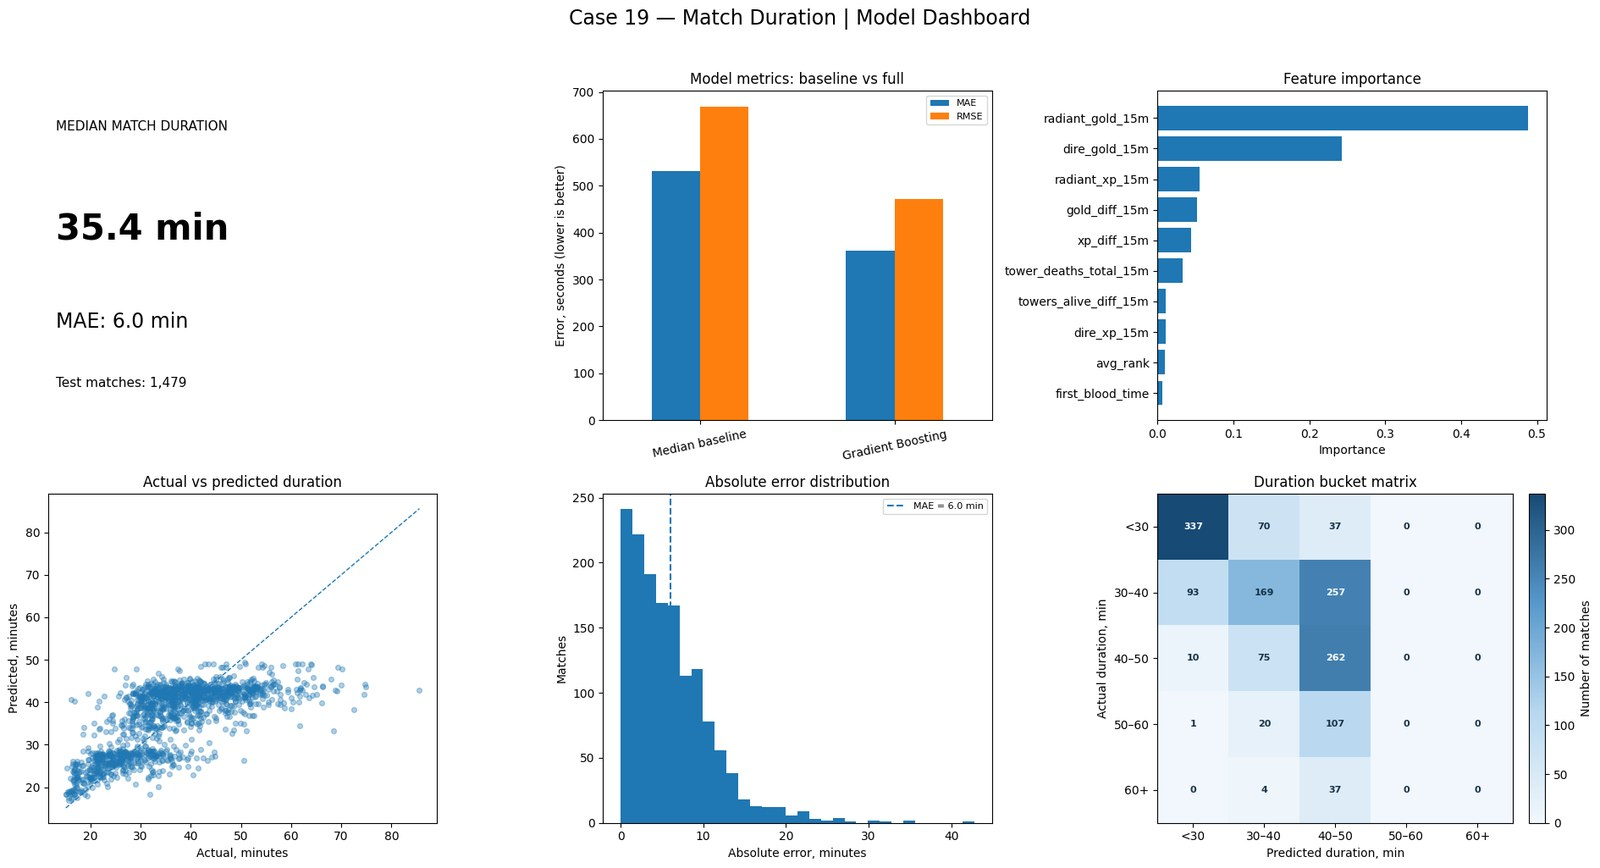


### 11.9. Сохранение экспериментальных артефактов и ограничения

Сохраняем модель, метрики и таблицу ошибок локально. Это не публикация модели в реестр платформы.

In [ ]:
if duration_mart_ready:
    duration_artifact_dir = Path("case19_duration_artifacts")
    duration_artifact_dir.mkdir(exist_ok=True)

    joblib.dump(
        {
            "model": duration_gbt,
            "features": list(X_duration.columns),
            "target": "duration",
            "target_unit": "seconds",
            "mart_table": DURATION_MART,
        },
        duration_artifact_dir / "case19_duration_model.joblib",
    )
    duration_metrics_df.to_csv(duration_artifact_dir / "case19_metrics.csv", index=False)
    duration_importance.to_csv(duration_artifact_dir / "case19_feature_importance.csv", index=False)
    duration_error_df.to_csv(duration_artifact_dir / "case19_holdout_errors.csv", index=False)

    print("Артефакты сохранены в:", duration_artifact_dir.resolve())

**Ограничения Duration:**
- `gold_amount_net_15m` — сумма записанных событий золота, а не текущее золото команды и не преимущество по золоту.
- `death_gold_event_count_15m` считает события с `reason='DEATH'`, а не обязательно все смерти.
- Отсутствующие event aggregates нельзя автоматически трактовать как нулевые значения; coverage flags должны сохраняться.
- Train/test split воспроизводим, но при наличии временных меток матчей для итоговой проверки предпочтительна дополнительная временная валидация.
- Положительный R² сам по себе недостаточен: обязательно анализировать MAE/RMSE в секундах и распределение ошибок.

# Итог проекта и бизнес-рекомендации

## Что показали три кейса

- **Roshan:** первый Roshan и доля контроля связаны с win rate; после первого убийства наблюдается плато. В очень длинных матчах связь ослабевает. Это описательная ассоциация, а не причинный эффект.
- **Winner:** раннее преимущество по золоту — сильный сигнал. Random Forest превосходит majority baseline на случайном holdout; до использования в live-аналитике нужны временная валидация и калибровка.
- **Duration:** Gradient Boosting снижает MAE и RMSE относительно глобального медианного baseline более чем на 25% на отложенной выборке. Гипотезы D1–D4 требуют отдельного анализа; следует сравнить модель также со средним/медианным baseline внутри игрового режима и оценить ошибки по диапазонам длительности.

## Практические рекомендации

1. Использовать контроль Рошана как контекстный индикатор командного преимущества, а не как гарантию победы; в затяжных матчах не опираться на него как на сильный разделитель.
2. Использовать раннее преимущество по золоту для live-аналитики как сигнал, а не как гарантированный прогноз. Перед применением модели Winner провести временную валидацию и проверку калибровки.
3. Представлять Duration как исследовательскую оценку, пока не выполнено сравнение с baseline внутри игрового режима и анализ ошибок по группам длительности.
4. На каждом слое контролировать ключи, дубликаты, временные границы и покрытие событий; сохранять coverage flags и различать «событие отсутствовало» и «данные не поступили».
5. Зафиксировать срез данных и SLA обновления витрин, а также мониторинг свежести и ошибок DAG.

**Общее ограничение:** результаты моделей и групповых сравнений зависят от качества ключей, покрытия источников и корректности baseline. Корреляция и feature importance не доказывают причинность.